# DATA PREPROCESSING

In [1]:
!pip list

Package                           Version
--------------------------------- -------------------
aext-assistant                    4.20.0
aext-assistant-server             4.20.0
aext-core                         4.20.0
aext-core-server                  4.20.0
aext_environments_server          4.20.0
aext-panels                       4.20.0
aext-panels-server                4.20.0
aext-project-filebrowser-server   4.20.0
aext-share-notebook               4.20.0
aext-share-notebook-server        4.20.0
aext-shared                       4.20.0
aext-toolbox                      4.20.0
aiobotocore                       2.25.0
aiodns                            3.5.0
aiohappyeyeballs                  2.6.1
aiohttp                           3.13.2
aioitertools                      0.12.0
aiosignal                         1.4.0
alabaster                         1.0.0
alembic                           1.17.2
altair                            6.0.0
anaconda-anon-usage               0.7.5
anaconda

In [84]:
# ================================
# ML PREPROCESSING PIPELINE (MNE)
# ================================

import os
import json
import numpy as np
import pandas as pd
from pathlib import Path
from datetime import datetime
import time

import mne
from mne.preprocessing import ICA
# label_components from mne_icalabel
from mne_icalabel import label_components

# ----------------
# CONFIGURATION
# ----------------
DATA_ROOT = r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci"
OUTPUT_DIR = os.path.join(DATA_ROOT, "processed_ml")
os.makedirs(OUTPUT_DIR, exist_ok=True)

SUBJECTS = ["sub-26", "sub-27", "sub-28", "sub-29"]
SESSIONS = ["ses-01", "ses-02", "ses-03"]

TASK_FILES = {
    "ZeroBack": "zeroBACK.set",
    "OneBack": "oneBACK.set",
    "TwoBack": "twoBACK.set",
    "MATB_easy": "MATBeasy.set",
    "MATB_med": "MATBmed.set",
    "MATB_diff": "MATBdiff.set",
}

EPOCH_LENGTH = 5.0  # seconds
HP_FREQ = 1.0
LP_FREQ = 45.0
NOTCH_FREQ = 50.0
TARGET_SFREQ = 250
BAD_CH_STD_Z = 2.0
ICLABEL_PROB_THRESH = 0.90

USE_ICALABEL = True

# ================================
# LOAD CANONICAL EEG CHANNEL SET
# ================================
COMMON_CH_PATH = Path(DATA_ROOT) / "common_eeg_channels.json"
with open(COMMON_CH_PATH, "r") as f:
    COMMON_EEG_CHANNELS = json.load(f)["common_channels"]

assert len(COMMON_EEG_CHANNELS) == 62, "Expected exactly 62 common EEG channels"

# Prepare a standard montage object (used only for interpolation)
try:
    STD_MONTAGE = mne.channels.make_standard_montage("standard_1020")
except Exception:
    STD_MONTAGE = None

# ================================
# SESSION QC
# ================================
SESSION_QC_ROWS = []

def append_qc_row(subj, ses, task, log_dict, epochs, bads, ica_info):
    SESSION_QC_ROWS.append({
        "subject": subj,
        "session": ses,
        "task": task,
        "n_epochs": len(epochs),
        "bad_channels": ", ".join(bads) if bads else "None",
        "n_bad_channels": len(bads),
        "interpolated": bool(log_dict["steps"].get("bad_channels_interpolated")),
        "ica_attempted": ica_info.get("attempted", False),
        "ica_n_components": ica_info.get("n_components", None),
        "ica_removed": ", ".join(map(str, ica_info.get("excluded", []))) if ica_info.get("excluded") else "None",
        "n_ica_removed": len(ica_info.get("excluded", [])) if ica_info.get("excluded") else 0,
        "ica_error": ica_info.get("error", None),
        "montage_attached": log_dict["steps"].get("montage_attached", False),
        "montage_missing_channels": ", ".join(log_dict["steps"].get("montage_missing_channels", [])),
    })

def finalize_session_qc(subj, ses, output_dir):
    if not SESSION_QC_ROWS:
        return
    df = pd.DataFrame(SESSION_QC_ROWS)
    print("\n=== QC SUMMARY TABLE ===")
    print(df.to_string(index=False))
    out_csv = Path(output_dir) / f"{subj}_{ses}_QC_summary.csv"
    try:
        df.to_csv(out_csv, index=False)
        print(f"QC table saved to: {out_csv}")
    except PermissionError:
        ts = datetime.now().strftime("%Y%m%d_%H%M%S")
        alt = Path(output_dir) / f"{subj}_{ses}_QC_summary_{ts}.csv"
        df.to_csv(alt, index=False)
        print(f"Warning: Could not overwrite {out_csv} (PermissionError). Saved to {alt} instead.")
    SESSION_QC_ROWS.clear()

# ----------------
# HELPERS
# ----------------
def log(msg):
    print(f"[{datetime.now().strftime('%H:%M:%S')}] {msg}")

def detect_bad_channels_std(raw, z_thresh=2.0):
    data = raw.get_data(picks="eeg")
    ch_stds = np.std(data, axis=1)
    mean_std = np.mean(ch_stds)
    std_std = np.std(ch_stds)
    thresh = mean_std + z_thresh * std_std
    bads = [raw.ch_names[i] for i, s in enumerate(ch_stds) if s > thresh]
    return bads, {
        "mean_std": float(mean_std),
        "std_std": float(std_std),
        "threshold": float(thresh),
    }

def sanitize_for_json(obj):
    """Recursively convert numpy types to Python native types for json dumping."""
    if isinstance(obj, dict):
        return {sanitize_for_json(k): sanitize_for_json(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [sanitize_for_json(x) for x in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, (np.floating, np.float32, np.float64)):
        return float(obj)
    if isinstance(obj, (np.integer, np.int32, np.int64)):
        return int(obj)
    if obj is None:
        return None
    # pandas/numpy scalar types
    try:
        if hasattr(obj, 'item'):
            return sanitize_for_json(obj.item())
    except Exception:
        pass
    return obj

# ----------------
# MAIN LOOP
# ----------------
for subj in SUBJECTS:
    for ses in SESSIONS:

        base_path = Path(DATA_ROOT) / subj / ses
        eeg_path = base_path / "eeg"
        # we intentionally do not use subject get_chanlocs for interpolation by default
        chanlocs_path = base_path / "chanlocs" / "get_chanlocs.txt"

        log(f"Processing {subj}, {ses}")

        for task, fname in TASK_FILES.items():
            set_path = eeg_path / fname
            if not set_path.exists():
                log(f"  ! Missing file: {set_path}")
                continue

            log(f"  -> Loading {task}")

            log_dict = {
                "subject": subj,
                "session": ses,
                "task": task,
                "file": str(set_path),
                "steps": {},
            }

            try:
                raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
            except Exception as e:
                log(f"Failed to load: {e}")
                continue

            log_dict["n_channels_raw"] = len(raw.ch_names)
            log_dict["sfreq_original"] = raw.info["sfreq"]

            # ---------- PICK canonical channels (only those present)
            channels_to_pick = [c for c in COMMON_EEG_CHANNELS if c in raw.ch_names]
            missing = sorted(set(COMMON_EEG_CHANNELS) - set(raw.ch_names))
            extra = sorted(set(raw.ch_names) - set(COMMON_EEG_CHANNELS))
            if not channels_to_pick:
                log(f"  ! No canonical channels present in file {set_path.name}. Skipping.")
                continue
            if missing:
                log(f"  ! Missing expected EEG channels: {missing}")

            raw.pick_channels(channels_to_pick, ordered=True)
            log_dict["steps"]["channel_set"] = "canonical_62"
            log_dict["steps"]["missing_channels"] = missing
            log_dict["steps"]["extra_channels_dropped"] = extra
            log_dict["n_channels_eeg"] = len(raw.ch_names)

            # ---------- NO subject-specific montage (avoid unstable subject coords)
            log_dict["steps"]["montage_attached"] = False
            log_dict["steps"]["montage_missing_channels"] = missing

            # ---------- RESAMPLE & FILTER
            raw.resample(TARGET_SFREQ)
            raw.filter(HP_FREQ, LP_FREQ, fir_design="firwin")
            raw.notch_filter(NOTCH_FREQ)
            log_dict["steps"]["resampled"] = TARGET_SFREQ
            log_dict["steps"]["filtered"] = {"highpass": HP_FREQ, "lowpass": LP_FREQ, "notch": NOTCH_FREQ}

            # ---------- EPOCHING (fixed lengths)
            epochs = mne.make_fixed_length_epochs(raw, duration=EPOCH_LENGTH, preload=True, overlap=0.0)
            log_dict["n_epochs"] = len(epochs)

            # ---------- BAD CHANNELS detection
            bads, bad_info = detect_bad_channels_std(raw, BAD_CH_STD_Z)
            log_dict["steps"]["bad_channel_stats"] = bad_info
            log_dict["steps"]["bad_channels_detected"] = bads

            # decide interp candidates (prefer channels with finite locs; else use STD_MONTAGE)
            interp_bads = []
            skipped_bads = []
            for ch in bads:
                try:
                    idx = epochs.ch_names.index(ch)
                    loc = epochs.info["chs"][idx]["loc"][:3]
                    if np.isfinite(loc).all():
                        interp_bads.append(ch)
                    else:
                        skipped_bads.append(ch)
                except Exception:
                    skipped_bads.append(ch)

            did_interpolate = False
            if interp_bads and len(interp_bads) < len(epochs.ch_names):
                if STD_MONTAGE is not None:
                    try:
                        # attach template montage just for interpolation
                        epochs.set_montage(STD_MONTAGE, match_case=False)
                        epochs.info["bads"] = interp_bads
                        epochs.interpolate_bads(reset_bads=True)
                        did_interpolate = True
                        log(f"  > Interpolated bad channels (using standard_1020): {interp_bads}")
                    except Exception as e:
                        log(f"  ! Interpolation failed with standard_1020: {e}")
                        epochs.info["bads"] = interp_bads
                else:
                    log("  ! No standard montage available, skipping interpolation.")
                    epochs.info["bads"] = interp_bads
            else:
                if interp_bads:
                    log(f"  ! Skipping interpolation (all channels flagged or none flagged). interp_bads={interp_bads}")
                epochs.info["bads"] = skipped_bads or interp_bads

            log_dict["steps"]["bad_channels_interpolated"] = interp_bads if did_interpolate else []
            log_dict["steps"]["bad_channels_skipped_no_pos"] = skipped_bads

            # ---------- REFERENCE ----------
            try:
                epochs.set_eeg_reference("average", projection=False)
                log_dict["steps"]["average_reference"] = True
            except Exception as e:
                log(f"  ! Average reference failed: {e}")
                log_dict["steps"]["average_reference"] = False

            # ---------- ICA (ICLabel) ----------
            ica_info = {"attempted": True}
            try:
                # Fit ICA on subset for speed
                N_EPOCHS_FOR_ICA = min(90, len(epochs))
                epochs_for_fit = epochs[:N_EPOCHS_FOR_ICA].copy()
            
                ica = ICA(
                    n_components=0.99,
                    method="infomax",
                    fit_params=dict(extended=True),
                    random_state=97,
                    max_iter="auto",
                )
            
                log(f"  > Fitting ICA on {len(epochs_for_fit)} epochs (subset) ...")
                ica.fit(epochs_for_fit)
                log(f"  > ICA fitted (n_components_ = {ica.n_components_})")
            
                excluded = []
            
                if USE_ICALABEL:
                    # ICLabel REQUIRES 1–100 Hz data so we will make copy ONLY for labeling
                    epochs_for_iclabel = epochs_for_fit.copy()
                    try:
                        epochs_for_iclabel.filter(1.0, 100.0, fir_design="firwin", verbose=False)
                    except Exception:
                        log("  ! Warning: could not apply 1–100 Hz filter for ICLabel")
            
                    try:
                        iclab = label_components(epochs_for_iclabel, ica, method="iclabel")
                    except Exception as e:
                        iclab = None
                        log(f"  ! ICLabel failed with exception: {e}")
            
                    
                    # ICLabel returns:
                    # - labels: list[str]
                    # - y_pred_proba: 1D array = confidence of predicted label
                    labels = None
                    probs = None
                    if isinstance(iclab, dict):
                        labels = iclab.get("labels", None)
                        probs = iclab.get("y_pred_proba", None)
            
                    if labels is None or probs is None:
                        log("  ! ICLabel gave no usable output — fallback to heuristics")
                        # fallback heuristics
                        try:
                            if "Fp1" in epochs.ch_names:
                                eog_idx, _ = ica.find_bads_eog(epochs, ch_name="Fp1")
                                excluded.extend(map(int, eog_idx))
                                if eog_idx:
                                    log(f"    > find_bads_eog flagged: {eog_idx}")
                        except Exception as e:
                            log(f"  ! EOG fallback failed: {e}")
                    else:
                        # MAIN ICLabel LOGIC
                        for i, (lab, p) in enumerate(zip(labels, probs)):
                            lab_low = lab.lower()
                            if lab_low in {"eye blink", "muscle artifact", "heart beat", "line noise", "channel noise"} and float(p) >= ICLABEL_PROB_THRESH:
                                excluded.append(int(i))
            
                excluded = sorted(set(excluded))
                ica.exclude = excluded
            
                if excluded:
                    log(f"  > Excluding ICA components: {excluded}")
                    epochs = ica.apply(epochs)
                else:
                    log("  > No ICA components excluded")
            
                ica_info.update({
                    "n_components": int(ica.n_components_),
                    "excluded": excluded,
                    "iclabel_prob_thresh": ICLABEL_PROB_THRESH,
                })
            
            except Exception as e:
                ica_info["error"] = str(e)
                log(f"  ! ICA block failed: {e}")
            
            log_dict["steps"]["ica"] = ica_info

            # store qc row
            append_qc_row(
                subj=subj,
                ses=ses,
                task=task,
                log_dict=log_dict,
                epochs=epochs,
                bads=bads,
                ica_info=ica_info,
            )

            # ---------- SAVE ----------
            out_fpath = Path(OUTPUT_DIR) / f"{subj}_{ses}_{task}_clean-epo.fif"
            epochs.save(out_fpath, overwrite=True)
            log_dict["output_fif"] = str(out_fpath)

            # sanitize log_dict for JSON (convert np types -> native)
            safe_log = sanitize_for_json(log_dict)
            with open(out_fpath.with_suffix(".json"), "w") as f:
                json.dump(safe_log, f, indent=2)

            log(f"Saved {out_fpath.name}")

        finalize_session_qc(subj, ses, OUTPUT_DIR)

log("DONE")

[17:10:06] Processing sub-26, ses-01
[17:10:06]   -> Loading ZeroBack
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:174: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:174: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:174: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 825 samples (3.300 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge

C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:294: RuntimeWarning: The provided Epochs instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for Raw and Epochs instances).
  iclab = label_components(epochs_for_iclabel, ica, method="iclabel")


[17:10:35]   > Excluding ICA components: [0, 3, 24]
Applying ICA to Epochs instance
    Transforming to ICA space (27 components)
    Zeroing out 3 ICA components
    Projecting back using 62 PCA components
[17:10:35] Saved sub-26_ses-01_ZeroBack_clean-epo.fif
[17:10:35]   -> Loading OneBack
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


...

[17:42:10]   > No ICA components excluded
[17:42:10] Saved sub-29_ses-03_MATB_med_clean-epo.fif
[17:42:10]   -> Loading MATB_diff
NOTE: pick_channels() is a legacy function. New code should use inst.pick(...).


C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:174: RuntimeWarning: Limited 1 annotation(s) that were expanding outside the data range.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:174: RuntimeWarning: The data contains 'boundary' events, indicating data discontinuities. Be cautious of filtering and epoching around these events.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)
C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:174: RuntimeWarning: Not setting position of 1 ecg channel found in montage:
['ECG1']
Consider setting the channel types to be of EEG/sEEG/ECoG/DBS/fNIRS using inst.set_channel_types before calling inst.set_montage, or omit these channels when creating your montage.
  raw = mne.io.read_raw_eeglab(set_path, preload=True, verbose=False)


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 1 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 1.00
- Lower transition bandwidth: 1.00 Hz (-6 dB cutoff frequency: 0.50 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 825 samples (3.300 s)

Filtering raw data in 1 contiguous segment
Setting up band-stop filter from 49 - 51 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandstop filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 49.38
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 49.12 Hz)
- Upper passband edge

C:\Users\User\AppData\Local\Temp\ipykernel_17592\2435500935.py:294: RuntimeWarning: The provided Epochs instance is not filtered between 1 and 100 Hz. ICLabel was designed to classify features extracted from an EEG dataset bandpass filtered between 1 and 100 Hz (see the 'filter()' method for Raw and Epochs instances).
  iclab = label_components(epochs_for_iclabel, ica, method="iclabel")


[17:42:33]   > Excluding ICA components: [3]
Applying ICA to Epochs instance
    Transforming to ICA space (20 components)
    Zeroing out 1 ICA component
    Projecting back using 62 PCA components
[17:42:33] Saved sub-29_ses-03_MATB_diff_clean-epo.fif

=== QC SUMMARY TABLE ===
subject session      task  n_epochs bad_channels  n_bad_channels  interpolated  ica_attempted  ica_n_components  ica_removed  n_ica_removed ica_error  montage_attached montage_missing_channels
 sub-29  ses-03  ZeroBack        62         None               0         False           True                23 0, 1, 11, 17              4      None             False                         
 sub-29  ses-03   OneBack        63         None               0         False           True                21     0, 2, 15              3      None             False                         
 sub-29  ses-03   TwoBack        63         None               0         False           True                24        0, 20              2  

# LABELING AND FEATURE EXTRACTION 

In [13]:
import os
import re
from pathlib import Path
import json
import numpy as np
import pandas as pd
import mne
from datetime import datetime
from scipy.stats import skew, kurtosis

# ---------------- USER CONFIG ----------------
DATA_ROOT = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci")
OUTPUT_DIR = DATA_ROOT / "processed_ml"   
RSME_PATH = DATA_ROOT / "RSME.txt"       
OUT_DIR = DATA_ROOT / "features"        
OUT_DIR.mkdir(parents=True, exist_ok=True)

# PSD params
FMIN = 1.0
FMAX = 45.0
N_PER_SEG = 256  # for PSD resolution (with sfreq=250 this gives ~1 Hz bins)

# Bands
BANDS = {
    "delta": (1, 4),
    "theta": (4, 8),
    "alpha": (8, 13),
    "beta":  (13, 30),
    "gamma": (30, 45),
}

# 6 ROIs (we keep the original 3 + expansions).
REGIONS = {
    "frontal": ["F3", "F1", "Fz", "F2", "F4", "FC3", "FC1", "FCz", "FC2", "FC4"],
    "central": ["C3", "C1", "C2", "C4", "CP3", "CP1", "CPz", "CP2", "CP4"],
    "parietal": ["P3", "P1", "Pz", "P2", "P4"],
    "occipital": ["O1", "Oz", "O2", "PO3", "POz", "PO4"],
    "temporal": ["T7", "T8", "FT7", "FT8", "TP7", "TP8", "FT9", "FT10", "TP10"],
    "parieto_occipital": ["P3", "P1", "Pz", "P2", "P4", "PO3", "POz", "PO4", "O1", "Oz", "O2"],
}

# The 10 channels used by the paper (for per-channel features and Riemannian baseline)
PAPER_CHS = ["F3","Fz","F4","FCz","C3","C4","CPz","P3","Pz","P4"]

# Task name canonicalization (how tasks appear in filenames)
TASK_LOW = {"ZeroBack", "MATB_easy"}
TASK_MED = {"OneBack", "MATB_med"}
TASK_HIGH = {"TwoBack", "MATB_diff"}

# Optional behavior
SAVE_METADATA = True
VERBOSE = True

# ------------------------------------------------

def read_rsme(rsme_path):
    """Read the RSME file into a pandas DataFrame. Expects columns: sbj,Session,Condition,Score,condition"""
    df = pd.read_csv(rsme_path)
    # Normalize condition strings
    df['condition'] = df['condition'].astype(str).str.strip()
    return df


def subj_ses_task_from_fname(fname):
    stem = Path(fname).stem  # removes extension
    parts = stem.split("_")

    subj = next((p for p in parts if p.lower().startswith("sub-")), None)
    ses  = next((p for p in parts if p.lower().startswith("ses-")), None)

    KNOWN_TASKS = {
        "ZeroBack", "OneBack", "TwoBack",
        "MATB_easy", "MATB_med", "MATB_diff"
    }

    stem_low = stem.lower()
    task = next((t for t in KNOWN_TASKS if t.lower() in stem_low), None)

    return subj, ses, task


def subjnum_from_subjid(subj):
    if subj is None:
        return None
    m = re.search(r"\d+", subj)
    return int(m.group(0)) if m else None


def sesnum_from_sesid(ses):
    if ses is None:
        return None
    m = re.search(r"\d+", ses)
    return int(m.group(0)) if m else None

# ---------------- signal feature helpers ----------------

def psd_epochs(epochs, fmin=1.0, fmax=45.0, n_per_seg=256):
    psd = epochs.compute_psd(
        method="welch",
        fmin=fmin,
        fmax=fmax,
        n_per_seg=n_per_seg,
        picks="eeg",
        verbose=False,
    )
    psds = psd.get_data()
    freqs = psd.freqs
    return psds, freqs


def band_mean_power_from_psd(psds, freqs, band):
    lo, hi = band
    mask = (freqs >= lo) & (freqs < hi)
    if not mask.any():
        return np.zeros(psds.shape[:2])  # n_epochs x n_channels
    return psds[:, :, mask].mean(axis=2)


def spectral_entropy_from_psd(psds, eps=1e-12):
    p = psds / (psds.sum(axis=2, keepdims=True) + eps)
    ent = -np.sum(p * np.log2(p + eps), axis=2)
    return ent


def spectral_flatness_from_psd(psds, eps=1e-12):
    geo = np.exp(np.mean(np.log(psds + eps), axis=2))
    arith = np.mean(psds + eps, axis=2)
    flatness = geo / arith
    return flatness


def hjorth_parameters(data):
    activity = data.var(axis=2)
    diff1 = np.diff(data, axis=2)
    mobility = np.sqrt(diff1.var(axis=2) / (activity + 1e-12))
    diff2 = np.diff(diff1, axis=2)
    mobility2 = np.sqrt(diff2.var(axis=2) / (diff1.var(axis=2) + 1e-12))
    complexity = mobility2 / (mobility + 1e-12)
    return activity, mobility, complexity


def aggregate_region_features(ch_names, channel_values, region_def=REGIONS):
    ch_to_idx = {c: i for i, c in enumerate(ch_names)}
    n_epochs = channel_values.shape[0]
    out = {}
    for rname, chlist in region_def.items():
        idxs = [ch_to_idx[c] for c in chlist if c in ch_to_idx]
        if len(idxs) == 0:
            out[rname] = np.full((n_epochs,), np.nan)
        else:
            out[rname] = np.nanmean(channel_values[:, idxs], axis=1)
    return out

# ---------------- main processing ----------------

def process_all_epochs(output_dir=OUTPUT_DIR, rsme_path=RSME_PATH):
    rsme_df = read_rsme(rsme_path) if rsme_path.exists() else None
    file_list = sorted(Path(output_dir).glob("*_clean-epo.fif"))

    rows_all = []    # accumulate epoch-level rows (3-class)
    rows_binary = [] # only low vs high
    rows_reg = []    # with rsme score (if available)

    for fpath in file_list:
        subj, ses, task = subj_ses_task_from_fname(fpath.name)
        if subj is None or ses is None or task is None:
            if VERBOSE:
                print(f"[WARN] Could not parse subj/ses/task from {fpath.name} — skipping")
            continue

        subj_num = subjnum_from_subjid(subj)
        ses_num = sesnum_from_sesid(ses)

        epochs = mne.read_epochs(fpath, preload=True, verbose=False)
        n_epochs = len(epochs)
        if n_epochs == 0:
            if VERBOSE:
                print(f"[INFO] No epochs in {fpath.name}, skipping")
            continue

        # compute PSDs
        psds, freqs = psd_epochs(epochs, fmin=FMIN, fmax=FMAX, n_per_seg=N_PER_SEG)
        ch_names = epochs.ch_names

        # band absolute power (per epoch x channel)
        band_abs = {}
        for bname, band in BANDS.items():
            band_abs[bname] = band_mean_power_from_psd(psds, freqs, band)  # n_epochs x n_ch

        # total power (1-45Hz)
        total_power = psds.sum(axis=2)

        # relative band power
        band_rel = {}
        for bname in BANDS:
            band_rel[bname] = band_abs[bname] / (total_power + 1e-12)

        # spectral entropy & flatness (per epoch x channel)
        spec_entropy = spectral_entropy_from_psd(psds)
        spec_flatness = spectral_flatness_from_psd(psds)

        # time-domain features
        data = epochs.get_data()  # n_epochs x n_channels x n_times
        activity, mobility, complexity = hjorth_parameters(data)
        var = np.var(data, axis=2)

        # additional time-domain stats per channel
        ch_mean = data.mean(axis=2)
        ch_skew = skew(data, axis=2, bias=False)
        ch_kurt = kurtosis(data, axis=2, bias=False)

        # --- Build region-level aggregated maps for reuse ---
        region_band_abs = {b: aggregate_region_features(ch_names, band_abs[b]) for b in BANDS}
        region_band_rel = {b: aggregate_region_features(ch_names, band_rel[b]) for b in BANDS}
        region_entropy = aggregate_region_features(ch_names, spec_entropy)
        region_flatness = aggregate_region_features(ch_names, spec_flatness)
        region_activity = aggregate_region_features(ch_names, activity)
        region_mobility = aggregate_region_features(ch_names, mobility)
        region_complexity = aggregate_region_features(ch_names, complexity)
        region_variance = aggregate_region_features(ch_names, var)
        region_mean = aggregate_region_features(ch_names, ch_mean)
        region_skew = aggregate_region_features(ch_names, ch_skew)
        region_kurt = aggregate_region_features(ch_names, ch_kurt)

        # dictionary of arrays per feature name -> length n_epochs
        feat_dict = {
            "subject": np.array([subj]*n_epochs),
            "subject_num": np.array([subj_num]*n_epochs),
            "session": np.array([ses]*n_epochs),
            "session_num": np.array([ses_num]*n_epochs),
            "task": np.array([task]*n_epochs),
            "epoch_idx": np.arange(n_epochs),
            "source_file": np.array([str(fpath.name)]*n_epochs),
        }

        # aggregate channel-wise arrays per region for band abs & rel
        for bname in BANDS:
            for r, arr in region_band_abs[bname].items():
                feat_dict[f"{r}_{bname}_abs"] = arr
            for r, arr in region_band_rel[bname].items():
                feat_dict[f"{r}_{bname}_rel"] = arr

        # add spectral entropy & flatness (region)
        for r, arr in region_entropy.items():
            feat_dict[f"{r}_spec_entropy"] = arr
        for r, arr in region_flatness.items():
            feat_dict[f"{r}_spec_flatness"] = arr

        # Hjorth & variance & time stats (region)
        for r in region_activity:
            feat_dict[f"{r}_activity"] = region_activity[r]
            feat_dict[f"{r}_mobility"] = region_mobility[r]
            feat_dict[f"{r}_complexity"] = region_complexity[r]
            feat_dict[f"{r}_variance"] = region_variance[r]
            feat_dict[f"{r}_mean"] = region_mean[r]
            feat_dict[f"{r}_skew"] = region_skew[r]
            feat_dict[f"{r}_kurtosis"] = region_kurt[r]

        # Additional regional band ratios
        for r in REGIONS.keys():
            theta = feat_dict.get(f"{r}_theta_abs")
            alpha = feat_dict.get(f"{r}_alpha_abs")
            beta = feat_dict.get(f"{r}_beta_abs")
            # ensure arrays exist; if not, fill with NaN
            if theta is None:
                theta = np.full((n_epochs,), np.nan)
            if alpha is None:
                alpha = np.full((n_epochs,), np.nan)
            if beta is None:
                beta = np.full((n_epochs,), np.nan)

            feat_dict[f"{r}_theta_div_alpha"] = theta / (alpha + 1e-12)
            feat_dict[f"{r}_beta_div_alpha"] = beta / (alpha + 1e-12)
            feat_dict[f"{r}_thetabeta_div_alpha"] = (np.nan_to_num(theta, 0) + np.nan_to_num(beta, 0)) / (alpha + 1e-12)
            feat_dict[f"{r}_beta_div_alpha_plus_theta"] = beta / (alpha + theta + 1e-12)

        # frontal - parieto_occipital differences for theta/alpha/beta
        for band in ['theta','alpha','beta']:
            f_arr = feat_dict.get(f"frontal_{band}_abs", np.full((n_epochs,), np.nan))
            p_arr = feat_dict.get(f"parieto_occipital_{band}_abs", np.full((n_epochs,), np.nan))
            feat_dict[f"frontal_minus_parieto_{band}"] = f_arr - p_arr

        # --- Per-channel features for PAPER_CHS (band abs + theta/alpha ratio) ---
        ch_to_idx = {c: i for i, c in enumerate(ch_names)}
        for ch in PAPER_CHS:
            if ch in ch_to_idx:
                idx = ch_to_idx[ch]
                for bname in BANDS:
                    arr = band_abs[bname][:, idx]
                    feat_dict[f"chan_{ch}_{bname}_abs"] = arr
                # theta/alpha ratio per channel
                t = band_abs['theta'][:, idx]
                a = band_abs['alpha'][:, idx]
                feat_dict[f"chan_{ch}_theta_div_alpha"] = t / (a + 1e-12)
            else:
                # fill with nan if channel missing
                for bname in BANDS:
                    feat_dict[f"chan_{ch}_{bname}_abs"] = np.full((n_epochs,), np.nan)
                feat_dict[f"chan_{ch}_theta_div_alpha"] = np.full((n_epochs,), np.nan)

        # Build label columns
        if task in TASK_LOW:
            class3 = 0
        elif task in TASK_MED:
            class3 = 1
        elif task in TASK_HIGH:
            class3 = 2
        else:
            class3 = np.nan

        feat_dict["label_3class"] = np.array([class3]*n_epochs)

        # binary: only keep rows for low and high (omit medium)
        if class3 in (0, 2):
            feat_dict["label_binary"] = np.array([0 if class3==0 else 1]*n_epochs)
        else:
            feat_dict["label_binary"] = np.array([np.nan]*n_epochs)

        # RSME regression: match by subject_num, session_num and condition string equals task (if rsme available)
        rsme_score = np.nan
        if rsme_df is not None:
            mask = (rsme_df['sbj'] == subj_num) & (rsme_df['Session'] == ses_num) & (rsme_df['condition'].str.lower() == task.lower())
            matched = rsme_df.loc[mask]
            if len(matched) >= 1:
                rsme_score = matched['Score'].values[0]
        feat_dict["rsme_score"] = np.array([rsme_score]*n_epochs)

        # Convert feat_dict to DataFrame rows
        df_local = pd.DataFrame(feat_dict)

        # Save metadata once (feature list, rois, bands, paper channels)
        if SAVE_METADATA and not OUT_DIR.joinpath("features_metadata.json").exists():
            meta = {
                "feature_columns": [c for c in df_local.columns if c not in ("subject","subject_num","session","session_num","task","epoch_idx","source_file")],
                "rois": list(REGIONS.keys()),
                "bands": BANDS,
                "paper_channels": PAPER_CHS,
                "label_map_3class": {"ZeroBack":0,"OneBack":1,"TwoBack":2,"MATB_easy":0,"MATB_med":1,"MATB_diff":2},
                "n_subjects_expected": None
            }
            with open(OUT_DIR.joinpath("features_metadata.json"), "w") as mf:
                json.dump(meta, mf, indent=2)

        # append to master lists
        rows_all.append(df_local)

        # rows for binary dataset: drop medium
        df_bin = df_local.dropna(subset=["label_binary"]).copy()
        if not df_bin.empty:
            rows_binary.append(df_bin)

        # regression (keep any rows, rsme may be NaN if not present)
        rows_reg.append(df_local)

        if VERBOSE:
            print(f"[{datetime.now().strftime('%H:%M:%S')}] Processed {fpath.name}: epochs={n_epochs}, subj={subj}, ses={ses}, task={task}")

    # concatenate everything and save
    if rows_all:
        df_all = pd.concat(rows_all, ignore_index=True)
        out_all = OUT_DIR / "features_all_3class.csv"
        df_all.to_csv(out_all, index=False)
        print(f"Saved 3-class features to: {out_all}")
    else:
        print("No 3-class rows produced.")

    if rows_binary:
        df_bin_all = pd.concat(rows_binary, ignore_index=True)
        out_bin = OUT_DIR / "features_binary_low_high.csv"
        df_bin_all.to_csv(out_bin, index=False)
        print(f"Saved binary features to: {out_bin}")
    else:
        print("No binary rows produced (no low/high epochs found).")

    if rows_reg:
        df_reg = pd.concat(rows_reg, ignore_index=True)
        out_reg = OUT_DIR / "features_with_rsme.csv"
        df_reg.to_csv(out_reg, index=False)
        print(f"Saved regression features to: {out_reg}")
    else:
        print("No regression rows produced.")

    # update metadata with final counts
    if SAVE_METADATA:
        try:
            meta_path = OUT_DIR.joinpath("features_metadata.json")
            meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}
            meta["n_epochs_total"] = int(df_all.shape[0]) if rows_all else 0
            meta["n_subjects_detected"] = int(df_all["subject_num"].nunique()) if rows_all else 0
            meta_path.write_text(json.dumps(meta, indent=2))
        except Exception:
            pass

if __name__ == "__main__":
    process_all_epochs()

[05:29:58] Processed sub-01_ses-01_MATB_diff_clean-epo.fif: epochs=59, subj=sub-01, ses=ses-01, task=MATB_diff
[05:30:01] Processed sub-01_ses-01_MATB_easy_clean-epo.fif: epochs=59, subj=sub-01, ses=ses-01, task=MATB_easy
[05:30:03] Processed sub-01_ses-01_MATB_med_clean-epo.fif: epochs=59, subj=sub-01, ses=ses-01, task=MATB_med
[05:30:06] Processed sub-01_ses-01_OneBack_clean-epo.fif: epochs=82, subj=sub-01, ses=ses-01, task=OneBack
[05:30:09] Processed sub-01_ses-01_TwoBack_clean-epo.fif: epochs=78, subj=sub-01, ses=ses-01, task=TwoBack
[05:30:12] Processed sub-01_ses-01_ZeroBack_clean-epo.fif: epochs=79, subj=sub-01, ses=ses-01, task=ZeroBack
[05:30:14] Processed sub-01_ses-02_MATB_diff_clean-epo.fif: epochs=59, subj=sub-01, ses=ses-02, task=MATB_diff
[05:30:16] Processed sub-01_ses-02_MATB_easy_clean-epo.fif: epochs=59, subj=sub-01, ses=ses-02, task=MATB_easy
[05:30:21] Processed sub-01_ses-02_MATB_med_clean-epo.fif: epochs=59, subj=sub-01, ses=ses-02, task=MATB_med
[05:30:25] Proc

# DATA EXPLORATION

In [15]:
import pandas as pd, numpy as np, json
from pathlib import Path
OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features")

df_all = pd.read_csv(OUT_DIR / "features_all_3class.csv")
df_bin = pd.read_csv(OUT_DIR / "features_binary_low_high.csv")
df_reg = pd.read_csv(OUT_DIR / "features_with_rsme.csv")
meta = json.load(open(OUT_DIR / "features_metadata.json"))

print("Loaded: all, bin, reg shapes:", df_all.shape, df_bin.shape, df_reg.shape)
print("Metadata keys:", list(meta.keys()))
print("First 5 columns (all):", df_all.columns[:20].tolist())

Loaded: all, bin, reg shapes: (32737, 211) (21831, 211) (32737, 211)
Metadata keys: ['feature_columns', 'rois', 'bands', 'paper_channels', 'label_map_3class', 'n_subjects_expected', 'n_epochs_total', 'n_subjects_detected']
First 5 columns (all): ['subject', 'subject_num', 'session', 'session_num', 'task', 'epoch_idx', 'source_file', 'frontal_delta_abs', 'central_delta_abs', 'parietal_delta_abs', 'occipital_delta_abs', 'temporal_delta_abs', 'parieto_occipital_delta_abs', 'frontal_delta_rel', 'central_delta_rel', 'parietal_delta_rel', 'occipital_delta_rel', 'temporal_delta_rel', 'parieto_occipital_delta_rel', 'frontal_theta_abs']


In [16]:
# basic column info
print(df_all.dtypes.value_counts())

# NaN fraction per column (top 30)
nan_frac = df_all.isna().mean().sort_values(ascending=False)
print("Top NaN fractions (>=0.01):")
print(nan_frac[nan_frac>=0.01].head(40))

# numeric summary for features only
meta_feats = meta["feature_columns"]
num_feats = [c for c in meta_feats if c in df_all.columns]
print("Number of feature columns in metadata:", len(num_feats))
print(df_all[num_feats].describe().T.loc[:, ["min","25%","50%","75%","max"]].head(20))

float64    203
object       4
int64        4
Name: count, dtype: int64
Top NaN fractions (>=0.01):
label_binary    0.333140
rsme_score      0.015121
dtype: float64
Number of feature columns in metadata: 204
                                      min           25%           50%  \
frontal_delta_abs            3.401700e-13  1.541603e-12  2.291485e-12   
central_delta_abs            2.802479e-13  1.062864e-12  1.556193e-12   
parietal_delta_abs           2.383702e-13  1.455303e-12  2.173260e-12   
occipital_delta_abs          3.762624e-13  2.112418e-12  3.201637e-12   
temporal_delta_abs           5.192439e-13  2.031487e-12  3.164295e-12   
parieto_occipital_delta_abs  3.838024e-13  1.868593e-12  2.785176e-12   
frontal_delta_rel            3.082581e-03  1.727422e-02  2.230416e-02   
central_delta_rel            3.427507e-03  1.803328e-02  2.284315e-02   
parietal_delta_rel           2.405383e-03  1.703505e-02  2.211794e-02   
occipital_delta_rel          1.448424e-03  1.282730e-02  1.7738

In [17]:
print("Subjects:", df_all["subject_num"].unique())
print("Epochs per subject:\n", df_all.groupby("subject_num")["epoch_idx"].count())
print("\n3-class counts:\n", df_all["label_3class"].value_counts(sort=False))
print("\nBinary counts (non-NaN):\n", df_all["label_binary"].value_counts(dropna=True, sort=False))
print("\nPer-subject 3-class crosstab:\n", pd.crosstab(df_all["subject_num"], df_all["label_3class"]))
print("\nPer-session 3-class crosstab:\n", pd.crosstab(df_all["session_num"], df_all["label_3class"]))

Subjects: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29]
Epochs per subject:
 subject_num
1     1193
2     1154
3     1155
4     1147
5     1140
6     1117
7     1129
8     1128
9     1131
10    1123
11    1151
12    1118
13    1137
14    1122
15    1113
16    1104
17    1106
18    1126
19    1126
20    1112
21    1134
22    1146
23    1106
24    1130
25    1127
26    1121
27    1106
28    1127
29    1108
Name: epoch_idx, dtype: int64

3-class counts:
 label_3class
2    10985
0    10846
1    10906
Name: count, dtype: int64

Binary counts (non-NaN):
 label_binary
1.0    10985
0.0    10846
Name: count, dtype: int64

Per-subject 3-class crosstab:
 label_3class    0    1    2
subject_num                
1             396  400  397
2             387  382  385
3             385  381  389
4             381  381  385
5             376  382  382
6             372  372  373
7             376  374  379
8             371  375  382
9             367  380  

In [18]:
from sklearn.feature_selection import VarianceThreshold
X = df_all[num_feats].values
vt = VarianceThreshold(threshold=1e-8).fit(X)
lowvar = [f for f, keep in zip(num_feats, vt.get_support()) if not keep]
print("Low-variance features (threshold=1e-8):", len(lowvar))
print(lowvar[:50])

Low-variance features (threshold=1e-8): 101
['frontal_delta_abs', 'central_delta_abs', 'parietal_delta_abs', 'occipital_delta_abs', 'temporal_delta_abs', 'parieto_occipital_delta_abs', 'frontal_theta_abs', 'central_theta_abs', 'parietal_theta_abs', 'occipital_theta_abs', 'temporal_theta_abs', 'parieto_occipital_theta_abs', 'frontal_alpha_abs', 'central_alpha_abs', 'parietal_alpha_abs', 'occipital_alpha_abs', 'temporal_alpha_abs', 'parieto_occipital_alpha_abs', 'frontal_beta_abs', 'central_beta_abs', 'parietal_beta_abs', 'occipital_beta_abs', 'temporal_beta_abs', 'parieto_occipital_beta_abs', 'frontal_gamma_abs', 'central_gamma_abs', 'parietal_gamma_abs', 'occipital_gamma_abs', 'temporal_gamma_abs', 'parieto_occipital_gamma_abs', 'frontal_activity', 'frontal_variance', 'frontal_mean', 'central_activity', 'central_variance', 'central_mean', 'parietal_activity', 'parietal_variance', 'parietal_mean', 'occipital_activity', 'occipital_variance', 'occipital_mean', 'temporal_activity', 'tempor

In [19]:
# count features with extreme percentiles (e.g., 99.9th >> 75th by factor)
extreme = []
for f in num_feats:
    p75 = df_all[f].quantile(0.75)
    p999 = df_all[f].quantile(0.999)
    if p75 == 0:
        continue
    if p999 / (p75 + 1e-12) > 100:   # arbitrary threshold
        extreme.append((f, float(p75), float(p999)))
print("Features with huge upper tails (showing up to 50):", len(extreme))
print(extreme[:50])

Features with huge upper tails (showing up to 50): 0
[]


In [20]:
# compute top absolute correlations (pairwise) to reveal redundant features
feats = df_all[num_feats].fillna(0)  # for corr calculation use 0 or consider dropping NaNs first
corr = feats.corr().abs()
# mask diagonal and find top pairs
np.fill_diagonal(corr.values, 0)
high_pairs = (corr.stack().reset_index().rename(columns={0:"abscorr"}).sort_values("abscorr", ascending=False))
print("Top 20 highly correlated feature pairs (>0.98):")
print(high_pairs[high_pairs["abscorr"]>0.98].head(20))

Top 20 highly correlated feature pairs (>0.98):
                           level_0                      level_1   abscorr
20503            temporal_activity            temporal_variance  1.000000
21938   parieto_occipital_activity   parieto_occipital_variance  1.000000
18242            parietal_variance            parietal_activity  1.000000
19677           occipital_variance           occipital_activity  1.000000
14763             frontal_activity             frontal_variance  1.000000
19068           occipital_activity           occipital_variance  1.000000
16198             central_activity             central_variance  1.000000
22547   parieto_occipital_variance   parieto_occipital_activity  1.000000
21112            temporal_variance            temporal_activity  1.000000
16807             central_variance             central_activity  1.000000
15372             frontal_variance             frontal_activity  1.000000
17633            parietal_activity            parietal_variance 

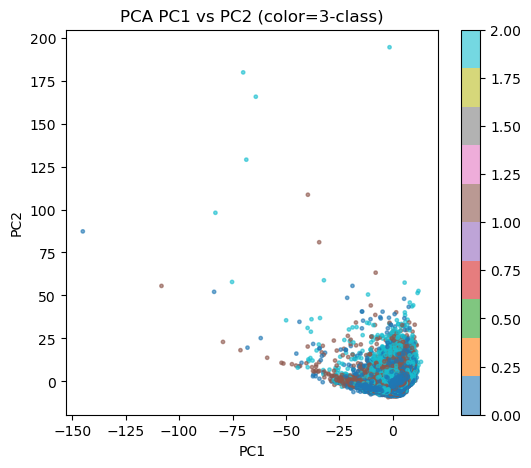

In [21]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
Xf = df_all[num_feats].copy().fillna(df_all[num_feats].median())
Xsc = StandardScaler().fit_transform(Xf)
pca = PCA(n_components=3).fit_transform(Xsc)
import matplotlib.pyplot as plt
plt.figure(figsize=(6,5))
labels = df_all["label_3class"].values
plt.scatter(pca[:,0], pca[:,1], c=labels, s=6, cmap="tab10", alpha=0.6)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("PCA PC1 vs PC2 (color=3-class)")
plt.colorbar()
plt.show()

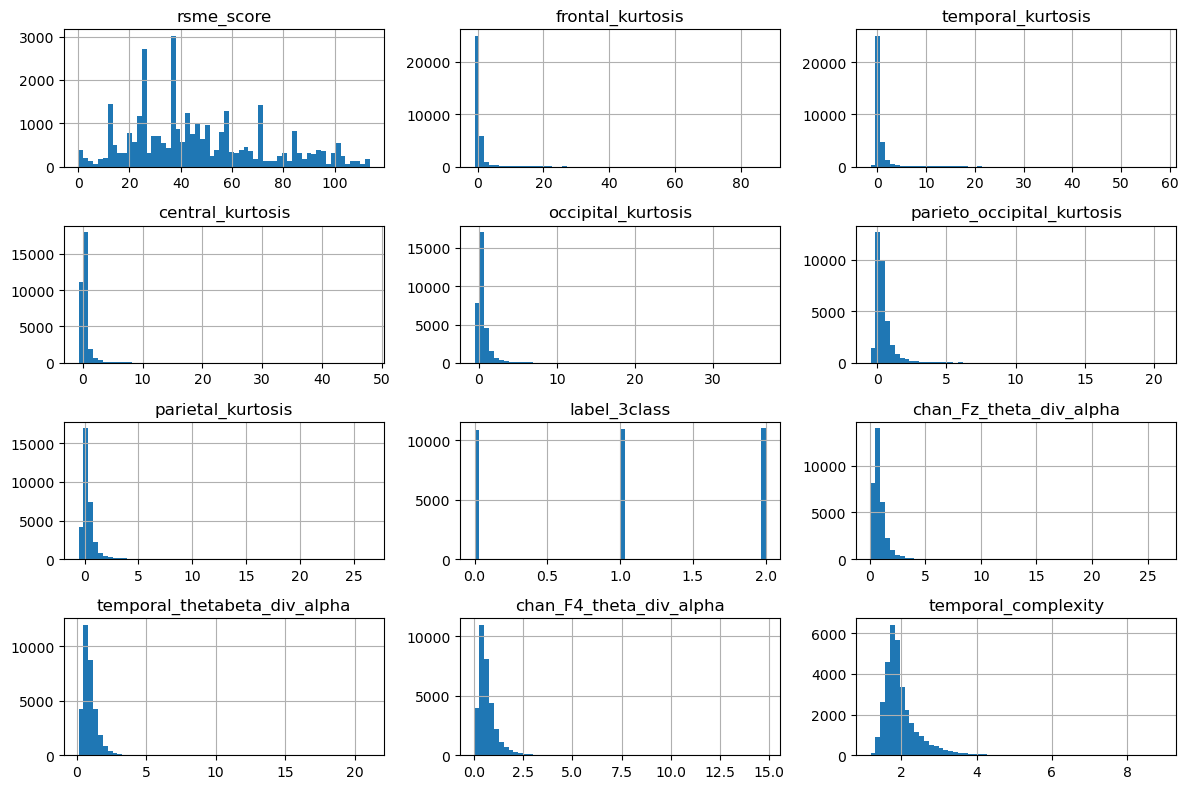

In [22]:
import matplotlib.pyplot as plt
# pick 12 top features by variance
vars_sorted = df_all[num_feats].var().sort_values(ascending=False)
top12 = vars_sorted.index[:12].tolist()
df_all[top12].hist(bins=60, figsize=(12,8))
plt.tight_layout()
plt.show()

In [23]:
# rows with many missing features
row_nan_frac = df_all[num_feats].isna().mean(axis=1)
print("Rows with >20% NaNs:", (row_nan_frac>0.2).sum())
print("Rows with any NaN:", (row_nan_frac>0).sum())
# show sample rows indices with many NaNs
print(df_all.loc[row_nan_frac>0.5, ["subject","session","task","epoch_idx","source_file"]].head(20))

Rows with >20% NaNs: 0
Rows with any NaN: 11216
Empty DataFrame
Columns: [subject, session, task, epoch_idx, source_file]
Index: []


In [24]:
if "rsme_score" in df_reg.columns:
    print("RSME stats on regression file:")
    print(df_reg["rsme_score"].describe())
    # check per-subject RSME variability
    print("Per-subject RSME mean:\n", df_reg.groupby("subject_num")["rsme_score"].mean())
else:
    print("No rsme_score column in regression file")

RSME stats on regression file:
count    32242.000000
mean        46.842500
std         25.919091
min          0.186890
25%         25.000000
50%         41.857240
75%         62.692416
max        113.622845
Name: rsme_score, dtype: float64
Per-subject RSME mean:
 subject_num
1     58.738855
2     37.250274
3     48.749935
4     19.023576
5     31.300877
6     25.505331
7     65.174378
8     74.102741
9     23.062010
10    68.820106
11    42.889795
12    23.526891
13    47.779986
14    42.551482
15    53.259169
16    40.941250
17    43.732350
18    56.584452
19    48.909943
20    40.238863
21    56.055086
22    65.277117
23    34.521082
24    45.626540
25    46.772822
26    36.914096
27    71.157923
28    49.853687
29    58.236143
Name: rsme_score, dtype: float64


In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
X = df_all[num_feats].values
y = df_all["label_3class"].values
groups = df_all["subject_num"].values

# small sample for speed: use 20k rows or all if smaller
nmax = min(4000, X.shape[0])
Xs = X[:nmax]; ys = y[:nmax]
pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42))])
pipe.fit(Xs, ys)
importances = pipe.named_steps["clf"].feature_importances_
imp_df = pd.DataFrame({"feature": num_feats, "imp": importances}).sort_values("imp", ascending=False).head(40)
print("Top 40 features by RF (on subset):")
print(imp_df)

Top 40 features by RF (on subset):
                          feature       imp
201                  label_3class  0.279968
202                  label_binary  0.174599
203                    rsme_score  0.094558
101             temporal_mobility  0.007243
16             temporal_theta_abs  0.006327
93             occipital_activity  0.005902
51            occipital_gamma_abs  0.005366
58             temporal_gamma_rel  0.005227
103             temporal_variance  0.005050
107    parieto_occipital_activity  0.005033
96             occipital_variance  0.004897
52             temporal_gamma_abs  0.004741
94             occipital_mobility  0.004703
108    parieto_occipital_mobility  0.004617
72               frontal_activity  0.004572
130      temporal_theta_div_alpha  0.004415
75               frontal_variance  0.004387
53    parieto_occipital_gamma_abs  0.004355
187             chan_P3_gamma_abs  0.004340
175             chan_C4_gamma_abs  0.004232
140    frontal_minus_parieto_beta  0.0041

# DATA PREPARATION

In [34]:
# Cell 0: load data & metadata
import pandas as pd, numpy as np, json
from pathlib import Path
OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features")

df = pd.read_csv(OUT_DIR / "features_all_3class.csv")
meta = json.load(open(OUT_DIR / "features_metadata.json"))
print("Loaded df:", df.shape)
print("Meta keys:", list(meta.keys()))
# build initial feature list from metadata (trust metadata)
all_meta_feats = [c for c in meta["feature_columns"] if c in df.columns]
len(all_meta_feats), all_meta_feats[:10]

Loaded df: (32737, 211)
Meta keys: ['feature_columns', 'rois', 'bands', 'paper_channels', 'label_map_3class', 'n_subjects_expected', 'n_epochs_total', 'n_subjects_detected']


(204,
 ['frontal_delta_abs',
  'central_delta_abs',
  'parietal_delta_abs',
  'occipital_delta_abs',
  'temporal_delta_abs',
  'parieto_occipital_delta_abs',
  'frontal_delta_rel',
  'central_delta_rel',
  'parietal_delta_rel',
  'occipital_delta_rel'])

In [35]:
# Cell 1: remove leakage columns and non-feature columns
leak_cols = {"label_3class","label_binary","rsme_score"}
nonfeat = {"subject","subject_num","session","session_num","task","epoch_idx","source_file"}

feat_cols = [c for c in all_meta_feats if c not in leak_cols and c not in nonfeat]
print("Features considered for modeling:", len(feat_cols))
# Save snapshot list
(pd.Series(feat_cols).to_csv(OUT_DIR/"feat_list_preclean.csv", index=False))

Features considered for modeling: 201


In [36]:
# Cell 2: drop exact-zero-variance features
X = df[feat_cols]
var = X.fillna(X.median()).var(axis=0)
zero_var = var[var == 0.0].index.tolist()
print("Exact zero-variance features:", len(zero_var))
feat_cols = [c for c in feat_cols if c not in zero_var]
print("After zero-var drop:", len(feat_cols))

Exact zero-variance features: 0
After zero-var drop: 201


In [37]:
# Cell 3: drop high-correlation duplicates (corr > TH)
TH = 0.98
Xf = df[feat_cols].fillna(df[feat_cols].median())
corr = Xf.corr().abs()

to_drop = set()
cols = corr.columns.tolist()
for i, a in enumerate(cols):
    if a in to_drop: 
        continue
    for b in cols[i+1:]:
        if corr.at[a,b] > TH:
            # tie-breaking rule: keep numeric name ordering (or choose domain-based)
            # Here we keep 'a' and drop 'b'
            to_drop.add(b)

print("Dropping", len(to_drop), "highly-correlated features (>", TH, ")")
feat_cols = [c for c in feat_cols if c not in to_drop]
print("Remaining features:", len(feat_cols))
# record what we dropped
pd.Series(sorted(list(to_drop))).to_csv(OUT_DIR/"feat_highcorr_dropped.csv", index=False)

Dropping 8 highly-correlated features (> 0.98 )
Remaining features: 193


In [38]:
# Cell 4: inspect skewness and mark candidates for log transform
from scipy.stats import skew
Xf = df[feat_cols].copy()
skews = Xf.fillna(Xf.median()).apply(lambda col: skew(col.values))
skews_sorted = skews.abs().sort_values(ascending=False)
skews_sorted.head(40)

# heuristic: mark features with abs(skew) > 3 for log transform (if all positive)
candidates = []
for c in skews.index:
    if abs(skews[c]) > 3:
        mn = Xf[c].min()
        if mn > 0:
            candidates.append(c)
# show a few
print("Log-transform candidates (positive & high skew):", len(candidates))
print(candidates[:30])

Log-transform candidates (positive & high skew): 108
['frontal_delta_abs', 'central_delta_abs', 'parietal_delta_abs', 'occipital_delta_abs', 'temporal_delta_abs', 'parieto_occipital_delta_abs', 'frontal_theta_abs', 'central_theta_abs', 'parietal_theta_abs', 'temporal_theta_abs', 'parieto_occipital_theta_abs', 'frontal_alpha_abs', 'central_alpha_abs', 'parietal_alpha_abs', 'occipital_alpha_abs', 'temporal_alpha_abs', 'parieto_occipital_alpha_abs', 'frontal_beta_abs', 'central_beta_abs', 'parietal_beta_abs', 'occipital_beta_abs', 'temporal_beta_abs', 'frontal_gamma_abs', 'central_gamma_abs', 'parietal_gamma_abs', 'occipital_gamma_abs', 'temporal_gamma_abs', 'central_spec_flatness', 'frontal_activity', 'frontal_complexity']


In [39]:
# Cell 5: PCA distance-based outliers (inspect top rows)
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

Xf = df[feat_cols].fillna(df[feat_cols].median())
Xsc = StandardScaler().fit_transform(Xf)
pca = PCA(n_components=6).fit_transform(Xsc)
dist = np.linalg.norm(pca[:, :3], axis=1)
# inspect top 30
idx_out = np.argsort(dist)[-30:][::-1]
out_df = df.loc[idx_out, ["subject","session","task","epoch_idx","source_file"]].copy()
out_df["pc_dist"] = dist[idx_out]
print(out_df.head(20))
# Save list for manual inspection
out_df.to_csv(OUT_DIR/"candidate_outliers.csv", index=False)

      subject session       task  epoch_idx  \
2243   sub-02  ses-03    TwoBack         24   
10543  sub-10  ses-01    TwoBack          4   
2263   sub-02  ses-03    TwoBack         44   
28942  sub-26  ses-02    TwoBack         45   
6148   sub-06  ses-01   ZeroBack         47   
6409   sub-06  ses-02    TwoBack          0   
2183   sub-02  ses-03    OneBack         26   
2919   sub-03  ses-02   MATB_med         35   
1816   sub-02  ses-02    OneBack         31   
11021  sub-10  ses-02   ZeroBack         35   
25065  sub-23  ses-01   MATB_med         35   
23297  sub-21  ses-02    TwoBack         44   
25077  sub-23  ses-01   MATB_med         47   
2193   sub-02  ses-03    OneBack         36   
26362  sub-24  ses-01   ZeroBack         23   
25088  sub-23  ses-01   MATB_med         58   
2293   sub-02  ses-03   ZeroBack         10   
23626  sub-21  ses-03    TwoBack          2   
12123  sub-11  ses-02    TwoBack         55   
1294   sub-02  ses-01  MATB_easy         42   

            

In [40]:
# Cell 6: apply log transforms if you decided on candidates, save cleaned CSV
LOG_CANDIDATES = []  # replace with list from Cell 4 if you choose
df_clean = df.copy()
for c in LOG_CANDIDATES:
    # shift if necessary to make positive
    mn = df_clean[c].min()
    if mn <= 0:
        shift = abs(mn) + 1e-9
    else:
        shift = 0
    df_clean[c] = np.log1p(df_clean[c] + shift)

# Save cleaned set (features only + identifiers + labels)
final_cols = ["subject","subject_num","session","session_num","task","epoch_idx","source_file"] + feat_cols + ["label_3class","label_binary","rsme_score"]
df_clean[final_cols].to_csv(OUT_DIR/"features_cleaned_planB_6rois.csv", index=False)

# Update metadata
meta2 = dict(meta)
meta2["cleaned_feature_list"] = feat_cols
meta2["dropped_zero_var"] = zero_var
meta2["dropped_highcorr_count"] = len(to_drop)
open(OUT_DIR/"features_metadata_cleaned.json","w").write(json.dumps(meta2, indent=2))
print("Saved cleaned features CSV and metadata.")

Saved cleaned features CSV and metadata.


In [41]:
import numpy as np
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, classification_report

# prepare X, y, groups (subject_num)
X = df_clean[feat_cols].values
y = df_clean["label_3class"].values
groups = df_clean["subject_num"].values

gkf = GroupKFold(n_splits=len(np.unique(groups)))
pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("fs", SelectKBest(score_func=f_classif, k=40)),   # adjust k (e.g., 25-50)
    ("clf", LogisticRegression(solver="saga", max_iter=5000, class_weight="balanced", random_state=42))
])

scores = []
cms = []
fold = 0
for train_idx, test_idx in gkf.split(X, y, groups):
    fold += 1
    pipe.fit(X[train_idx], y[train_idx])
    yp = pipe.predict(X[test_idx])
    bal = balanced_accuracy_score(y[test_idx], yp)
    scores.append(bal)
    cm = confusion_matrix(y[test_idx], yp, labels=[0,1,2])
    cms.append(cm)
    print(f"Fold {fold}: balanced_acc={bal:.3f}")

print("Mean balanced acc:", np.mean(scores), "±", np.std(scores))
agg_cm = sum(cms)
print("Aggregated confusion matrix (rows=true, cols=pred):")
print(agg_cm)

Fold 1: balanced_acc=0.366
Fold 2: balanced_acc=0.395
Fold 3: balanced_acc=0.581
Fold 4: balanced_acc=0.382
Fold 5: balanced_acc=0.440
Fold 6: balanced_acc=0.465
Fold 7: balanced_acc=0.385
Fold 8: balanced_acc=0.376
Fold 9: balanced_acc=0.444
Fold 10: balanced_acc=0.514
Fold 11: balanced_acc=0.400
Fold 12: balanced_acc=0.455
Fold 13: balanced_acc=0.334
Fold 14: balanced_acc=0.443
Fold 15: balanced_acc=0.443
Fold 16: balanced_acc=0.407
Fold 17: balanced_acc=0.379
Fold 18: balanced_acc=0.430
Fold 19: balanced_acc=0.404
Fold 20: balanced_acc=0.437
Fold 21: balanced_acc=0.372
Fold 22: balanced_acc=0.475
Fold 23: balanced_acc=0.365
Fold 24: balanced_acc=0.441
Fold 25: balanced_acc=0.369
Fold 26: balanced_acc=0.429
Fold 27: balanced_acc=0.388
Fold 28: balanced_acc=0.429
Fold 29: balanced_acc=0.525
Mean balanced acc: 0.4232596454088313 ± 0.053125938705129445
Aggregated confusion matrix (rows=true, cols=pred):
[[6260 2122 2464]
 [4958 2644 3304]
 [3816 2219 4950]]


In [42]:
from collections import Counter
fs = pipe.named_steps["fs"]
# we need to run selection per fold to accumulate:
sel_counter = Counter()
for train_idx, test_idx in gkf.split(X, y, groups):
    # train the fs on train set only
    Xtr = X[train_idx]
    ytr = y[train_idx]
    imputer = SimpleImputer(strategy="median").fit(Xtr)
    Xtr_imp = imputer.transform(Xtr)
    scaler = StandardScaler().fit(Xtr_imp)
    Xtr_sc = scaler.transform(Xtr_imp)
    skb = SelectKBest(f_classif, k=40).fit(Xtr_sc, ytr)
    chosen = [feat_cols[i] for i in skb.get_support(indices=True)]
    for f in chosen:
        sel_counter[f] += 1

# turn counts into frequency
n_folds = len(np.unique(groups))
stable = [(f, sel_counter[f]/n_folds) for f in feat_cols]
stable_sorted = sorted(stable, key=lambda x: x[1], reverse=True)
print("Top stable features (freq across folds):")
for f, freq in stable_sorted[:30]:
    print(f"{f}: {freq:.2f}")

Top stable features (freq across folds):
occipital_theta_abs: 1.00
parieto_occipital_theta_abs: 1.00
frontal_alpha_rel: 1.00
temporal_alpha_rel: 1.00
occipital_beta_abs: 1.00
occipital_gamma_abs: 1.00
parietal_gamma_rel: 1.00
temporal_gamma_rel: 1.00
parieto_occipital_gamma_rel: 1.00
frontal_complexity: 1.00
frontal_theta_div_alpha: 1.00
frontal_thetabeta_div_alpha: 1.00
parietal_theta_div_alpha: 1.00
parietal_thetabeta_div_alpha: 1.00
occipital_theta_div_alpha: 1.00
occipital_beta_div_alpha: 1.00
occipital_thetabeta_div_alpha: 1.00
temporal_theta_div_alpha: 1.00
temporal_beta_div_alpha: 1.00
temporal_thetabeta_div_alpha: 1.00
parieto_occipital_theta_div_alpha: 1.00
parieto_occipital_beta_div_alpha: 1.00
parieto_occipital_thetabeta_div_alpha: 1.00
parieto_occipital_beta_div_alpha_plus_theta: 1.00
chan_F3_theta_div_alpha: 1.00
chan_Fz_theta_abs: 1.00
chan_Fz_theta_div_alpha: 1.00
chan_F4_theta_div_alpha: 1.00
chan_P3_theta_div_alpha: 1.00
chan_Pz_theta_div_alpha: 1.00


In [43]:
# final_checkup
# Purpose: final automated data-prep check + small LOSO baseline sanity run

import json
import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter
from sklearn.feature_selection import VarianceThreshold, SelectKBest, f_classif
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.decomposition import PCA

# === CONFIG ===
OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features")
CLEANED_CSV = OUT_DIR / "features_cleaned_planB_6rois.csv"   # if you used this name
FALLBACK_CSV = OUT_DIR / "features_all_3class.csv"
METADATA = OUT_DIR / "features_metadata_cleaned.json"
REPORT_JSON = OUT_DIR / "final_checkup_report.json"
OUTLIERS_CSV = OUT_DIR / "final_outliers.csv"
DROPPED_CORR_CSV = OUT_DIR / "final_dropped_highcorr.csv"

# === LOAD ===
if CLEANED_CSV.exists():
    df = pd.read_csv(CLEANED_CSV)
    file_used = CLEANED_CSV.name
elif FALLBACK_CSV.exists():
    df = pd.read_csv(FALLBACK_CSV)
    file_used = FALLBACK_CSV.name
else:
    raise FileNotFoundError("Cannot find cleaned CSV or fallback CSV in OUT_DIR")

meta = {}
if METADATA.exists():
    try:
        meta = json.load(open(METADATA))
    except Exception:
        meta = {}

# Identify default columns
id_cols = ["subject","subject_num","session","session_num","task","epoch_idx","source_file"]
# Identify label cols (exists in df)
label_cols = [c for c in ("label_3class","label_binary","rsme_score") if c in df.columns]

# Build feature list: prefer cleaned list from metadata if present
if meta and "cleaned_feature_list" in meta:
    feat_cols = [c for c in meta["cleaned_feature_list"] if c in df.columns]
else:
    # fallback: all numeric columns except ids and labels
    feat_cols = [c for c in df.columns if c not in id_cols + label_cols and df[c].dtype in [np.float64, np.int64]]
    # also include numeric-features that are float
    extra = [c for c in df.columns if (c not in id_cols + label_cols) and (c not in feat_cols)]
    # keep only if numeric
    for c in extra:
        try:
            _ = pd.to_numeric(df[c].dropna().iloc[:10])
            feat_cols.append(c)
        except Exception:
            pass

report = {}
report["file_used"] = file_used
report["n_rows"] = int(df.shape[0])
report["n_columns_total"] = int(df.shape[1])
report["n_features_initial"] = int(len(feat_cols))
report["label_columns_present"] = label_cols

print("File used:", file_used)
print("Rows, cols:", df.shape)
print("Initial features considered:", len(feat_cols))

# === 1) Basic missingness and duplicates ===
nan_frac = df[feat_cols].isna().mean().sort_values(ascending=False)
report["num_features_with_any_NA"] = int((nan_frac > 0).sum())
report["top_missing_features"] = nan_frac[nan_frac > 0].head(20).to_dict()

row_na_counts = df[feat_cols].isna().sum(axis=1)
report["rows_with_any_na"] = int((row_na_counts > 0).sum())
report["rows_with_over_20pct_na"] = int((row_na_counts / len(feat_cols) > 0.2).sum())

dups = df.duplicated(subset=feat_cols + id_cols).sum()
report["duplicate_rows"] = int(dups)
print("Missingness: rows with any NA:", report["rows_with_any_na"], "; duplicates:", dups)

# === 2) Zero-variance features (exact) ===
var = df[feat_cols].fillna(df[feat_cols].median()).var(axis=0)
zero_var = var[var == 0.0].index.tolist()
report["zero_variance_features"] = zero_var
print("Zero-variance features:", len(zero_var))

# === 3) High-correlation groups (threshold) ===
TH = 0.98
Xf = df[feat_cols].fillna(df[feat_cols].median())
corr = Xf.corr().abs()
to_drop = set()
cols = corr.columns.tolist()
for i, a in enumerate(cols):
    if a in to_drop:
        continue
    for b in cols[i+1:]:
        if corr.at[a, b] > TH:
            to_drop.add(b)

report["num_highcorr_dropped"] = int(len(to_drop))
report["highcorr_dropped_sample"] = list(sorted(list(to_drop)))[:200]
# save dropped list
pd.Series(sorted(list(to_drop))).to_csv(DROPPED_CORR_CSV, index=False)

print("High-corr features to drop (>", TH, "):", len(to_drop))

# === 4) Feature distribution checks (skew) ===
from scipy.stats import skew
skews = Xf.apply(lambda col: float(skew(col.values)))
skew_df = pd.Series(skews).sort_values(ascending=False)
report["most_skewed_features"] = skew_df.head(20).to_dict()

# Identify strictly positive & highly skewed candidates for log1p
log_candidates = []
for c, s in skew_df.items():
    if abs(s) > 3:
        mn = Xf[c].min()
        if mn > 0:
            log_candidates.append(c)
report["log_transform_candidates_count"] = int(len(log_candidates))
report["log_transform_candidates"] = log_candidates[:]

# === 5) PCA outlier detection (PC distance) ===
pca = PCA(n_components=6)
Xsc = (Xf - Xf.mean(axis=0)) / (Xf.std(axis=0) + 1e-12)
p = pca.fit_transform(Xsc)
dist = np.linalg.norm(p[:, :3], axis=1)
top_out_idx = np.argsort(dist)[-50:][::-1]
out_df = df.loc[top_out_idx, id_cols + label_cols].copy()
out_df["pc_dist"] = dist[top_out_idx]
out_df.to_csv(OUTLIERS_CSV, index=False)
report["n_pca_outliers_saved"] = int(out_df.shape[0])

print("Saved top PCA outliers to:", OUTLIERS_CSV)

# === 6) Per-subject label balance ===
if "label_3class" in df.columns:
    ct_sub = df.groupby("subject_num")["label_3class"].value_counts().unstack(fill_value=0)
    report["per_subject_label_counts"] = ct_sub.to_dict()
    print("Per-subject label counts computed")

# === 7) Final cleaned feature list (after dropping zero-var + to_drop) ===
feat_cols_final = [c for c in feat_cols if c not in zero_var and c not in to_drop]
report["n_features_final"] = int(len(feat_cols_final))
report["final_features"] = feat_cols_final[:]

# === 8) Sanity modeling: LOSO baseline (SelectKBest inside fold) ===
print("Running quick LOSO baseline (safe)...")
X = df[feat_cols_final].values
y = df["label_3class"].values
groups = df["subject_num"].values

gkf = GroupKFold(n_splits=len(np.unique(groups)))
pipe = Pipeline([
    ("imp", SimpleImputer(strategy="median")),
    ("sc", StandardScaler()),
    ("fs", SelectKBest(score_func=f_classif, k=min(40, len(feat_cols_final)))),
    ("clf", LogisticRegression(solver="saga", max_iter=3000, class_weight="balanced", random_state=42))
])

scores = []
cms = []
fold = 0
for train_idx, test_idx in gkf.split(X, y, groups):
    fold += 1
    pipe.fit(X[train_idx], y[train_idx])
    yp = pipe.predict(X[test_idx])
    bal = balanced_accuracy_score(y[test_idx], yp)
    scores.append(float(bal))
    cms.append(confusion_matrix(y[test_idx], yp, labels=[0,1,2]).tolist())

report["loso_balanced_acc_mean"] = float(np.mean(scores))
report["loso_balanced_acc_std"] = float(np.std(scores))
report["loso_per_fold"] = [float(s) for s in scores]
report["loso_agg_confusion"] = np.sum(cms, axis=0).tolist()

print("LOSO balanced acc mean ± std:", report["loso_balanced_acc_mean"], report["loso_balanced_acc_std"])

# === 9) Small leakage sanity check ===
# ensure no exact label columns remain in feature list
leaks_in_features = [c for c in feat_cols_final if c in label_cols]
report["leaks_in_features"] = leaks_in_features
if leaks_in_features:
    print("WARNING: labels present in features:", leaks_in_features)

# === 10) Save report ===
open(REPORT_JSON, "w").write(json.dumps(report, indent=2))
print("Saved report to:", REPORT_JSON)
print("Final checks complete. Final feature count:", len(feat_cols_final))

File used: features_cleaned_planB_6rois.csv
Rows, cols: (32737, 203)
Initial features considered: 193
Missingness: rows with any NA: 0 ; duplicates: 0
Zero-variance features: 0
High-corr features to drop (> 0.98 ): 0
Saved top PCA outliers to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\final_outliers.csv
Per-subject label counts computed
Running quick LOSO baseline (safe)...
LOSO balanced acc mean ± std: 0.4232596454088313 0.053125938705129445
Saved report to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\final_checkup_report.json
Final checks complete. Final feature count: 193


In [6]:
# prepare_final_features.py
# After final_checkup; it reads the report for log candidates.
# Saves: features_final_prepared.csv and features_metadata_final.json

import json
import numpy as np
import pandas as pd
from pathlib import Path
from scipy.stats import mstats
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# ---------------- USER CONFIG ----------------
OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci/features")
INPUT_CSV = OUT_DIR / "features_cleaned_planB_6rois.csv"      # input cleaned file you already have
REPORT_JSON = OUT_DIR / "final_checkup_report.json"          # contains log candidates
OUTPUT_CSV = OUT_DIR / "features_final_prepared.csv"         # final prepared file (saved)
METADATA_OUT = OUT_DIR / "features_metadata_final.json"

# Transform options
APPLY_LOG = True            # apply np.log1p to the reported log candidates
WINSORIZE_REMAINDER = True  # if a log-candidate has nonpositive values (or not in list), winsorize instead
WINSOR_PCT = 0.005          # winsorize tails = 0.5% (change if you want)

# Outlier detection options
OUTLIER_ACTION = "mark"     # "mark" -> add is_outlier column; "remove" -> drop outliers from saved csv
OUTLIER_MULT = 6.0          # threshold = median + OUTLIER_MULT * MAD (robust)
PCA_N_COMPONENTS = 6

RANDOM_SEED = 42

# ---------------- load inputs ----------------
if not INPUT_CSV.exists():
    raise FileNotFoundError(f"Input CSV not found: {INPUT_CSV}")
df = pd.read_csv(INPUT_CSV)
report = {}
if REPORT_JSON.exists():
    report = json.load(open(REPORT_JSON))
else:
    print("Warning: final_checkup_report.json not found; proceeding without pre-computed log candidates.")
    
# Identify feature columns (exclude ids & labels)
id_cols = ["subject","subject_num","session","session_num","task","epoch_idx","source_file"]
label_cols = [c for c in ["label_3class","label_binary","rsme_score"] if c in df.columns]
feat_cols = [c for c in df.columns if c not in id_cols + label_cols]

print(f"Loaded {INPUT_CSV.name}: rows={len(df)}, initial features={len(feat_cols)}")

# ---------------- Build list of log candidates ----------------
log_candidates = None  
if not log_candidates:
    from scipy.stats import skew
    print("No log candidate list in report; computing skew-based candidates.")
    skews = df[feat_cols].fillna(df[feat_cols].median()).apply(lambda col: skew(col.values))
    # threshold for high skew
    log_candidates = list(skews[skews.abs() > 3].index)
    print(f"Detected {len(log_candidates)} skewed positives/negatives (abs(skew)>3).")

# Filter to features actually present
log_candidates = [c for c in log_candidates if c in feat_cols]
print(f"Log candidates present in dataset: {len(log_candidates)}")

# ---------------- Apply log1p or winsorization ----------------
df_pre = df.copy()
applied_log = []
applied_winsor = []

if APPLY_LOG:
    for c in log_candidates:
        if c not in df_pre.columns:
            continue
        col = df_pre[c]
        mn = col.min(skipna=True)
        # check strictly positive
        if mn is not None and mn > 0:
            # safe: log1p
            df_pre[c] = np.log1p(col)
            applied_log.append(c)
        else:
            # either has zeros/negatives or is ambiguous
            if WINSORIZE_REMAINDER:
                lower = col.quantile(WINSOR_PCT)
                upper = col.quantile(1.0 - WINSOR_PCT)
                df_pre[c] = col.clip(lower, upper)
                applied_winsor.append(c)
            else:
                # shift then log1p (less recommended)
                shift = abs(mn) + 1e-9
                df_pre[c] = np.log1p(col + shift)
                applied_log.append(c)

print(f"Applied log1p to {len(applied_log)} features; winsorized {len(applied_winsor)} features.")

# Optional: record transforms in metadata
transforms = {"log1p": applied_log, "winsorized": applied_winsor}

# ---------------- Recompute feature list after transforms ----------------
feat_cols_final = [c for c in df_pre.columns if c not in id_cols + label_cols]
print("Features for PCA/outlier detection:", len(feat_cols_final))

# ---------------- PCA-based outlier detection ----------------
X = df_pre[feat_cols_final].fillna(df_pre[feat_cols_final].median()).values
scaler = StandardScaler()
Xs = scaler.fit_transform(X)

pca = PCA(n_components=PCA_N_COMPONENTS, random_state=RANDOM_SEED)
P = pca.fit_transform(Xs)

# distance in PC1-3
pc_dist = np.linalg.norm(P[:, :3], axis=1)
med = np.median(pc_dist)
mad = np.median(np.abs(pc_dist - med)) + 1e-12
threshold = med + OUTLIER_MULT * mad

is_outlier = pc_dist > threshold
n_outliers = int(is_outlier.sum())

print(f"PCA outlier detection: median={med:.4f}, MAD={mad:.4f}, threshold={threshold:.4f}")
print(f"Detected outliers (PC-dist > threshold): {n_outliers}")

# attach flags and pc_dist
df_pre["pc_dist"] = pc_dist
df_pre["is_outlier"] = is_outlier.astype(int)

# Save the list of outliers for manual inspection
outliers_df = df_pre.loc[df_pre["is_outlier"] == 1, id_cols + ["pc_dist"]].copy()
outliers_csv = OUT_DIR / "final_pca_outliers_list.csv"
outliers_df.to_csv(outliers_csv, index=False)
print(f"Saved outlier list to: {outliers_csv}")

# ---------------- Action on outliers: mark or remove ----------------
if OUTLIER_ACTION == "mark":
    print("OUTLIER_ACTION='mark' -> outliers are flagged and retained in final CSV.")
    df_final = df_pre.copy()
elif OUTLIER_ACTION == "remove":
    print("OUTLIER_ACTION='remove' -> dropping detected outliers from final CSV.")
    df_final = df_pre.loc[df_pre["is_outlier"] == 0].copy()
    print(f"Rows before: {len(df_pre)}, after removal: {len(df_final)}")
else:
    raise ValueError("OUTLIER_ACTION must be 'mark' or 'remove'")

# ---------------- Save final prepared CSV and metadata ----------------
df_final.to_csv(OUTPUT_CSV, index=False)
meta_final = {
    "source_input_csv": str(INPUT_CSV.name),
    "n_rows_input": int(len(df)),
    "n_rows_output": int(len(df_final)),
    "n_features": len(feat_cols_final),
    "applied_transforms": transforms,
    "outlier_detection": {
        "method": "PCA_PC1-3_distance",
        "n_outliers": n_outliers,
        "threshold_median_plus_mult_MAD": float(threshold),
        "OUTLIER_MULT": OUTLIER_MULT,
        "OUTLIER_ACTION": OUTLIER_ACTION
    },
    "notes": "Log1p applied to positive-skewed candidates; winsorization applied to nonpositive skewed candidates if configured."
}
open(METADATA_OUT, "w").write(json.dumps(meta_final, indent=2))
print(f"Saved final prepared CSV to: {OUTPUT_CSV}")
print(f"Saved final metadata to: {METADATA_OUT}")

# Print short summary
print("\nSUMMARY")
print("Applied log1p to:", len(applied_log), "features")
print("Winsorized:", len(applied_winsor), "features")
print("Outliers detected:", n_outliers)
print("Final rows saved:", len(df_final))

Loaded features_cleaned_planB_6rois.csv: rows=32737, initial features=193
No log candidate list in report; computing skew-based candidates.
Detected 118 skewed positives/negatives (abs(skew)>3).
Log candidates present in dataset: 118
Applied log1p to 108 features; winsorized 10 features.
Features for PCA/outlier detection: 193
PCA outlier detection: median=6.4167, MAD=2.0411, threshold=18.6632
Detected outliers (PC-dist > threshold): 983
Saved outlier list to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\final_pca_outliers_list.csv
OUTLIER_ACTION='mark' -> outliers are flagged and retained in final CSV.


C:\Users\User\AppData\Local\Temp\ipykernel_740\2341982265.py:123: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pre["pc_dist"] = pc_dist
C:\Users\User\AppData\Local\Temp\ipykernel_740\2341982265.py:124: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_pre["is_outlier"] = is_outlier.astype(int)


Saved final prepared CSV to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\features_final_prepared.csv
Saved final metadata to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\features_metadata_final.json

SUMMARY
Applied log1p to: 108 features
Winsorized: 10 features
Outliers detected: 983
Final rows saved: 32737


In [7]:
# inspect_and_compare_outliers.py
import pandas as pd, numpy as np
from pathlib import Path
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold

OUT_DIR = Path(r"C:/Users/User/Jupyter projects/eeg-analysis/cog_bci\features")
FINAL_CSV = OUT_DIR / "features_final_prepared.csv"

print("Loading:", FINAL_CSV)
df = pd.read_csv(FINAL_CSV)

# identify columns
id_cols = ["subject","subject_num","session","session_num","task","epoch_idx","source_file"]
label_cols = [c for c in ["label_3class","label_binary","rsme_score"] if c in df.columns]
feat_cols = [c for c in df.columns if c not in id_cols + label_cols + ["pc_dist","is_outlier"]]

print("Rows, columns:", df.shape)
print("Feature count:", len(feat_cols))

# Basic outlier stats
n_outliers = int(df['is_outlier'].sum())
print("Total outliers flagged:", n_outliers, "(", n_outliers/len(df)*100, "% )")

# Per-subject outlier counts
out_by_subject = df.groupby("subject_num")["is_outlier"].sum().sort_values(ascending=False)
print("\nTop subjects by outlier counts (subject_num : count):")
print(out_by_subject.head(10))

# Per-session outlier counts
out_by_session = df.groupby(["subject_num","session_num"])["is_outlier"].sum().sort_values(ascending=False)
print("\nTop (subject,session) by outlier counts (show top 10):")
print(out_by_session.head(10))

# Per-task outlier counts
if "task" in df.columns:
    out_by_task = df.groupby("task")["is_outlier"].sum().sort_values(ascending=False)
    print("\nOutliers by task:")
    print(out_by_task)

# Show a sample of outlier rows (first 20)
print("\nSample outlier rows (first 20):")
print(df.loc[df["is_outlier"]==1, id_cols + ["pc_dist"]].head(20).to_string(index=False))

# Quick function to run LOSO baseline (SelectKBest + LR)
def loso_baseline(df_input, feat_cols, label="label_3class"):
    # prepare X,y,groups
    X = df_input[feat_cols].values
    y = df_input[label].values
    groups = df_input["subject_num"].values
    unique_groups = np.unique(groups)
    gkf = GroupKFold(n_splits=len(unique_groups))
    pipe = Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("fs", SelectKBest(score_func=f_classif, k=min(40, X.shape[1]))),
        ("clf", LogisticRegression(solver="saga", max_iter=3000, class_weight="balanced", random_state=42))
    ])
    fold_scores = []
    cms = []
    for train_idx, test_idx in gkf.split(X, y, groups):
        pipe.fit(X[train_idx], y[train_idx])
        yp = pipe.predict(X[test_idx])
        fold_scores.append(balanced_accuracy_score(y[test_idx], yp))
        cms.append(confusion_matrix(y[test_idx], yp, labels=[0,1,2]))
    return np.mean(fold_scores), np.std(fold_scores), np.sum(cms, axis=0), fold_scores

# LOSO on dataset with outliers kept
print("\nRunning LOSO baseline with outliers KEPT (flag present)...")
mean_k, std_k, cm_k, fold_scores_k = loso_baseline(df, feat_cols)
print("KEPT -> mean balanced acc: {:.4f} ± {:.4f}".format(mean_k, std_k))

# LOSO on dataset with outliers REMOVED
df_no = df.loc[df["is_outlier"]==0].reset_index(drop=True)
print("\nData with outliers removed: rows", len(df_no))
print("Running LOSO baseline with outliers REMOVED...")
mean_r, std_r, cm_r, fold_scores_r = loso_baseline(df_no, feat_cols)
print("REMOVED -> mean balanced acc: {:.4f} ± {:.4f}".format(mean_r, std_r))

# Save comparison
summary = {
    "rows_total": int(len(df)),
    "outlier_rows": int(n_outliers),
    "kept_mean_bal_acc": float(mean_k),
    "kept_std_bal_acc": float(std_k),
    "removed_mean_bal_acc": float(mean_r),
    "removed_std_bal_acc": float(std_r)
}
pd.Series(summary).to_csv(OUT_DIR / "outlier_loso_comparison_summary.csv")
print("\nSaved summary to outlier_loso_comparison_summary.csv")

# If removed case is better, consider investigating which subjects/sessions had many outliers:
out_by_subject.to_csv(OUT_DIR / "outlier_counts_by_subject.csv")
out_by_session.to_csv(OUT_DIR / "outlier_counts_by_session.csv")
print("Saved per-subject/session outlier counts.")

Loading: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\features_final_prepared.csv
Rows, columns: (32737, 205)
Feature count: 193
Total outliers flagged: 983 ( 3.0027186364052905 % )

Top subjects by outlier counts (subject_num : count):
subject_num
29    214
26    127
8      72
11     67
15     64
6      58
2      44
1      42
4      39
22     36
Name: is_outlier, dtype: int64

Top (subject,session) by outlier counts (show top 10):
subject_num  session_num
29           3              143
26           3               71
29           2               43
11           2               34
8            2               34
6            1               32
23           1               31
4            3               29
15           2               29
29           1               28
Name: is_outlier, dtype: int64

Outliers by task:
task
ZeroBack     273
OneBack      252
TwoBack      170
MATB_diff    130
MATB_med     113
MATB_easy     45
Name: is_outlier, dtype: int64

Sample outlier

C:\Users\User\anaconda3\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


KEPT -> mean balanced acc: 0.4279 ± 0.0525

Data with outliers removed: rows 31754
Running LOSO baseline with outliers REMOVED...
REMOVED -> mean balanced acc: 0.4254 ± 0.0616

Saved summary to outlier_loso_comparison_summary.csv
Saved per-subject/session outlier counts.


In [2]:
# compute_epoch_covs_memmap.py
# Memory-safe: process one epoch file at a time and write covariances to disk with np.memmap (float32).
import os, gc
from pathlib import Path
import numpy as np
import pandas as pd
import mne
from tqdm import tqdm
from collections import defaultdict

# ========== USER CONFIG ==========
CSV_PATH = r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\features_final_prepared.csv"
EPOCHS_FOLDER = r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\processed_ml"
OUT_FOLDER = r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap"
PREFERRED_CHANNELS = ["F3","Fz","F4","FCz","C3","C4","CPz","P3","Pz","P4"]  # paper channels
MIN_CHANNELS = 6
MEMMAP_FILENAME = "covs_float32.dat"
# =================================

os.makedirs(OUT_FOLDER, exist_ok=True)
csv_path = Path(CSV_PATH)
ep_root = Path(EPOCHS_FOLDER)
out_folder = Path(OUT_FOLDER)

print("Loading features CSV:", csv_path)
df = pd.read_csv(csv_path)
required_cols = {"source_file","epoch_idx","subject_num","label_3class"}
if not required_cols.issubset(set(df.columns)):
    raise ValueError(f"CSV missing required columns: {required_cols - set(df.columns)}")

# Build mapping: source_file -> list of (row_index, epoch_idx)
print("Building per-file mapping from CSV...")
file_map = defaultdict(list)
for idx, row in df.reset_index().iterrows():
    file_map[row["source_file"]].append((int(row["index"]), int(row["epoch_idx"])))

unique_files = sorted(file_map.keys())
print(f"Unique epoch files referenced in CSV: {len(unique_files)}")

# Quick scan to get common channels (reads only header/metadata)
print("Scanning a subset of files to compute common channel set...")
common_chs = None
bad_files = []
for fname in tqdm(unique_files):
    fpath = ep_root / fname
    if not fpath.exists():
        bad_files.append(str(fpath))
        continue
    # read epochs header only (preload=False) to get ch_names
    try:
        epochs_tmp = mne.read_epochs(fpath, preload=False, verbose=False)
        chs = set(epochs_tmp.ch_names)
    except Exception as e:
        bad_files.append(f"{fname} (error: {e})")
        continue
    if common_chs is None:
        common_chs = chs
    else:
        common_chs &= chs
    # free
    del epochs_tmp
    gc.collect()

if bad_files:
    raise FileNotFoundError("Some epoch files unreadable: \n" + "\n".join(bad_files))

common_chs = sorted(list(common_chs))
print(f"Channels common to all files: {len(common_chs)}")

# choose final channel ordering
final_ch_order = [c for c in PREFERRED_CHANNELS if c in common_chs]
if len(final_ch_order) < MIN_CHANNELS:
    print(f"Preferred channels present < {MIN_CHANNELS}. Falling back to first {MIN_CHANNELS} common channels.")
    final_ch_order = common_chs[:MIN_CHANNELS]
if len(final_ch_order) < MIN_CHANNELS:
    raise RuntimeError(f"Not enough common channels across files (found {len(final_ch_order)}).")

print("Final channel order used for covariance (n_ch={}):".format(len(final_ch_order)))
print(final_ch_order)
n_ch = len(final_ch_order)

# Prepare memmap file to hold covariances (float32)
n_rows = len(df)
covs_path = out_folder / MEMMAP_FILENAME
if covs_path.exists():
    print("Existing memmap found - removing it to rebuild.")
    covs_path.unlink()

print("Creating memmap for covariances:", covs_path)
covs_mem = np.memmap(covs_path, dtype='float32', mode='w+', shape=(n_rows, n_ch, n_ch))

# Prepare labels/groups/index_map and save (we can save them at end too)
labels = df["label_3class"].values.astype(np.int32)
groups = df["subject_num"].values.astype(np.int32)

# We'll iterate file-by-file, load epochs for that file only, compute covs for the referenced epoch indices, write to memmap,
# then delete epochs object and call gc.collect()
problematic = []
rows_processed = 0

def compute_cov_from_epoch_array(X_float32):
    # X_float32: (n_ch, n_times), dtype float32
    # compute unbiased covariance: (X @ X.T) / (T-1) after mean removal
    # subtract per-channel mean (in-place to save memory)
    X = X_float32 - X_float32.mean(axis=1, keepdims=True)
    T = X.shape[1]
    if T <= 1:
        return np.zeros((X.shape[0], X.shape[0]), dtype=np.float32)
    # manual matmul in float32
    cov = (X @ X.T) / float(T - 1)
    return cov.astype(np.float32)

print("Processing epoch files one-by-one and writing covariances to memmap...")
for fname in tqdm(unique_files):
    fpath = ep_root / fname
    if not fpath.exists():
        problematic.append(("missing_file", fname))
        continue
    # only process if this file is referenced in CSV
    if fname not in file_map:
        continue
    try:
        # load epochs for just this file (preload=True so we have epoch data to index)
        # This may allocate ~ (n_epochs_file * n_channels_file * n_times * 8 bytes) in memory temporarily,
        # but we free it immediately after processing this file
        epochs = mne.read_epochs(fpath, preload=True, verbose=False)
        file_chs = epochs.ch_names
        # map desired channel indices in this file
        try:
            idxs = [file_chs.index(ch) for ch in final_ch_order]
        except ValueError as e:
            problematic.append(("missing_channel_in_file", fname, str(e)))
            del epochs
            gc.collect()
            continue

        # get data for all epochs in this file once (this is fine for single file)
        data_all = epochs.get_data()  # shape (n_epochs_file, n_ch_file, n_times)
        # for each referenced (row_idx, epoch_idx) compute cov and write to memmap
        for (row_idx, eidx) in file_map[fname]:
            if eidx < 0 or eidx >= data_all.shape[0]:
                problematic.append(("bad_epoch_index", fname, eidx, data_all.shape[0], row_idx))
                continue
            ep = data_all[eidx]  # shape (n_ch_file, n_times)
            sel = ep[idxs, :].astype(np.float32)  # (n_ch, n_times) float32
            cov = compute_cov_from_epoch_array(sel)  # (n_ch, n_ch) float32
            covs_mem[row_idx, :, :] = cov
            rows_processed += 1

        # done with this file -> free memory
        del data_all
        del epochs
        gc.collect()

    except MemoryError as me:
        problematic.append(("memoryerror_loading_file", fname, str(me)))
        # try a more conservative fallback: load with preload=False then read epoch-by-epoch
        try:
            epochs = mne.read_epochs(fpath, preload=False, verbose=False)
            file_chs = epochs.ch_names
            idxs = [file_chs.index(ch) for ch in final_ch_order]
            # read and handle epoch-by-epoch to reduce peak memory (some mne internals may still allocate)
            n_epochs_file = len(epochs)
            for (row_idx, eidx) in file_map[fname]:
                if eidx < 0 or eidx >= n_epochs_file:
                    problematic.append(("bad_epoch_index_fallback", fname, eidx, n_epochs_file, row_idx))
                    continue
                ep = epochs.get_data()[eidx]  # may still allocate only the requested epoch
                sel = ep[idxs, :].astype(np.float32)
                cov = compute_cov_from_epoch_array(sel)
                covs_mem[row_idx, :, :] = cov
                rows_processed += 1
            del epochs
            gc.collect()
        except Exception as e2:
            problematic.append(("fallback_failed", fname, str(e2)))
            if 'epochs' in locals():
                del epochs
            gc.collect()
            continue

print("Rows processed:", rows_processed, "out of", n_rows)
if problematic:
    print("Some problematic entries encountered (first 10):")
    print(problematic[:10])

# Ensure memmap flush to disk
covs_mem.flush()
# Optionally, convert memmap to .npy (large) if you prefer:
# np.save(out_folder / "covs_float32.npy", np.array(covs_mem))

# Save labels/groups and index mapping (rows -> source_file, epoch_idx, subject, label)
np.save(out_folder / "labels.npy", labels)
np.save(out_folder / "groups.npy", groups)
df.reset_index()[["index","source_file","epoch_idx","subject_num","label_3class"]].to_csv(out_folder / "cov_index_map.csv", index=False)

print("Saved memmap covs to:", covs_path)
print("Saved labels/groups/index map.")
print("Done.")

Loading features CSV: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\features_final_prepared.csv
Building per-file mapping from CSV...
Unique epoch files referenced in CSV: 522
Scanning a subset of files to compute common channel set...


100%|████████████████████████████████████████████████████████████████████████████████| 522/522 [01:55<00:00,  4.53it/s]


Channels common to all files: 62
Final channel order used for covariance (n_ch=10):
['F3', 'Fz', 'F4', 'FCz', 'C3', 'C4', 'CPz', 'P3', 'Pz', 'P4']
Creating memmap for covariances: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\covs_float32.dat
Processing epoch files one-by-one and writing covariances to memmap...


100%|████████████████████████████████████████████████████████████████████████████████| 522/522 [02:44<00:00,  3.16it/s]

Rows processed: 32737 out of 32737
Saved memmap covs to: C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\covs_float32.dat
Saved labels/groups/index map.
Done.


In [3]:
# quick_covs_check.py
# Run basic sanity checks on the memmapped covariances produced earlier.

import os
import numpy as np
import pandas as pd
import mne
from pathlib import Path

# === CONFIG: point these to your files ===
PATH_MEMMAP = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\covs_float32.dat")
PATH_LABELS = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\labels.npy")
PATH_GROUPS = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\groups.npy")
PATH_INDEX = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\cov_index_map.csv")
CSV_FEATURES = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\features_final_prepared.csv")
EPOCHS_FOLDER = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\processed_ml")  # where epoch .fif files are

# channels you used when computing covs (must match order)
FINAL_CHS = ["F3","Fz","F4","FCz","C3","C4","CPz","P3","Pz","P4"]

# === load index/metadata ===
idx_map = pd.read_csv(PATH_INDEX)                     # columns: index, source_file, epoch_idx, subject_num, label_3class
labels = np.load(PATH_LABELS)
groups = np.load(PATH_GROUPS)

n_rows = idx_map.shape[0]
n_ch = len(FINAL_CHS)
print("Index rows:", n_rows, "channels:", n_ch)

# === map file size & memmap open ===
dtype = np.float32
expected_shape = (n_rows, n_ch, n_ch)
print("Memmap file exists:", PATH_MEMMAP.exists(), "size (MB):", PATH_MEMMAP.stat().st_size / 1024**2)
covs = np.memmap(PATH_MEMMAP, dtype=dtype, mode="r", shape=expected_shape)

# === 1) Basic shape/dtype checks ===
print("memmap dtype:", covs.dtype, "shape:", covs.shape)
print("labels shape:", labels.shape, "groups shape:", groups.shape)

# === 2) Symmetry + positive (semi-)definiteness check on small random sample ===
rng = np.random.default_rng(0)
sample_idx = rng.choice(np.arange(n_rows), size=min(20, n_rows), replace=False)
sym_max = 0.0
min_eig = 1e9
bad_sym = []
bad_eigs = []
for i in sample_idx:
    C = covs[i]
    # symmetry
    sdiff = np.max(np.abs(C - C.T))
    if sdiff > sym_max:
        sym_max = sdiff
    if sdiff > 1e-5:
        bad_sym.append((i, sdiff))
    # small eigenvalues
    eigs = np.linalg.eigvalsh(C)
    mev = eigs.min()
    if mev < -1e-5:
        bad_eigs.append((i, float(mev)))
    if mev < min_eig:
        min_eig = mev

print("Symmetry max abs-diff (sample):", sym_max)
print("Num large-sym-errors:", len(bad_sym), "Num negative-eig-cases:", len(bad_eigs), "min_eig:", min_eig)

# === 3) Spot-check against recomputed covariance for a few rows (load epoch file and recompute) ===
# This is the most important check: recompute covariance for a few random rows from their original epoch file.
def compute_cov_from_epoch_array(X):
    # X shape (n_ch, n_times) np.float32
    X = X - X.mean(axis=1, keepdims=True)
    T = X.shape[1]
    if T <= 1:
        return np.zeros((X.shape[0], X.shape[0]), dtype=np.float32)
    cov = (X @ X.T) / float(T - 1)
    return cov.astype(np.float32)

recompute_failures = []
for row in sample_idx[:8]:
    rowrec = idx_map.iloc[row]
    fname = rowrec["source_file"]
    eidx = int(rowrec["epoch_idx"])
    fpath = EPOCHS_FOLDER / fname
    if not fpath.exists():
        recompute_failures.append((row, "file_missing", fpath))
        continue
    # load epochs for this file and recompute epoch index
    ep = mne.read_epochs(fpath, preload=True, verbose=False)
    # map final channels -> file channels
    try:
        idxs = [ep.ch_names.index(ch) for ch in FINAL_CHS]
    except ValueError as e:
        recompute_failures.append((row, "channel_missing", str(e)))
        del ep
        continue
    if eidx < 0 or eidx >= len(ep):
        recompute_failures.append((row, "bad_epoch_index", eidx))
        del ep
        continue
    arr = ep.get_data()[eidx]            # shape (n_ch_file, n_times)
    sel = arr[idxs, :].astype(np.float32) # (n_ch, n_times)
    cov_re = compute_cov_from_epoch_array(sel)
    cov_saved = covs[row]
    diff = np.linalg.norm(cov_re - cov_saved)          # Frobenius norm
    rel = diff / (np.linalg.norm(cov_re) + 1e-12)
    print(f"row {row}: file={fname} epoch={eidx} frob_diff={diff:.6g} rel={rel:.6g}")
    # cleanup
    del ep

print("Recompute failures (first 10):", recompute_failures[:10])

# === 4) Compare diagonal (variances) to your CSV variance features (optional) ===
if CSV_FEATURES.exists():
    df_feat = pd.read_csv(CSV_FEATURES)
    # pick same sample row, find variance from memmap diagonal and value from 'frontal_variance' etc.
    # Here we compare channel variances (diagonal) aggregated to ROI 'central_variance' only if you have matching fields.
    print("CSV features available for quick cross-check. Showing example diagonals for 3 sample rows:")
    for r in sample_idx[:3]:
        diag = np.diag(covs[r])
        print(f" row {r} diag (first 5):", diag[:5])

# === 5) class-mean covariances and simple distance check ===
classes = np.unique(labels)
print("Labels present:", classes)
mean_covs = {}
for c in classes:
    ids = np.where(labels == c)[0]
    mean_covs[c] = covs[ids].mean(axis=0)
# compute pairwise Frobenius distances
for a in classes:
    for b in classes:
        if a < b:
            d = np.linalg.norm(mean_covs[a] - mean_covs[b])
            print(f"Frob dist between class {a} and {b}: {d:.4f}")

# === Wrap-up: save a short JSON/text summary ===
summary = {
    "n_rows": int(n_rows),
    "n_ch": int(n_ch),
    "memmap_dtype": str(covs.dtype),
    "memmap_size_MB": PATH_MEMMAP.stat().st_size / 1024**2,
    "sym_max_sample": float(sym_max),
    "min_eig_sample": float(min_eig),
    "n_recompute_failures": len(recompute_failures)
}
import json
with open(Path(PATH_MEMMAP).parent / "covs_check_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Saved summary:", Path(PATH_MEMMAP).parent / "covs_check_summary.json")
print("All checks done.")

Index rows: 32737 channels: 10
Memmap file exists: True size (MB): 12.488174438476562
memmap dtype: float32 shape: (32737, 10, 10)
labels shape: (32737,) groups shape: (32737,)
Symmetry max abs-diff (sample): 0.0
Num large-sym-errors: 0 Num negative-eig-cases: 0 min_eig: 1.3955658e-13
row 29873: file=sub-27_ses-02_MATB_easy_clean-epo.fif epoch=46 frob_diff=0 rel=0
row 10072: file=sub-09_ses-03_MATB_med_clean-epo.fif epoch=25 frob_diff=0 rel=0
row 8827: file=sub-08_ses-03_MATB_diff_clean-epo.fif epoch=40 frob_diff=0 rel=0
row 30611: file=sub-28_ses-01_MATB_easy_clean-epo.fif epoch=50 frob_diff=0 rel=0
row 16724: file=sub-15_ses-03_MATB_diff_clean-epo.fif epoch=37 frob_diff=0 rel=0
row 19855: file=sub-18_ses-02_OneBack_clean-epo.fif epoch=27 frob_diff=0 rel=0
row 18329: file=sub-17_ses-01_MATB_med_clean-epo.fif epoch=49 frob_diff=0 rel=0
row 31774: file=sub-29_ses-01_MATB_med_clean-epo.fif epoch=27 frob_diff=0 rel=0
Recompute failures (first 10): []
CSV features available for quick cross

In [4]:
# precise_covs_diagnostics.py
import numpy as np
import pandas as pd
from pathlib import Path

PATH_MEMMAP = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\covs_float32.dat")
PATH_LABELS = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\labels.npy")
PATH_INDEX = Path(r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\cov_index_map.csv")

idx_map = pd.read_csv(PATH_INDEX)
labels = np.load(PATH_LABELS)
n_rows = idx_map.shape[0]
n_ch = int(np.sqrt((np.memmap(PATH_MEMMAP, dtype=np.float32, mode='r').size) / n_rows))

covs = np.memmap(PATH_MEMMAP, dtype=np.float32, mode="r", shape=(n_rows, n_ch, n_ch))

print("Total rows:", n_rows, "channels:", n_ch)
# class counts
(unique, counts) = np.unique(labels, return_counts=True)
print("Class counts:")
for u,c in zip(unique, counts):
    print(" ", u, c)

# compute class-mean covariances with good precision (float64 accumulator)
mean_covs = {}
for u in unique:
    idxs = np.where(labels == u)[0]
    mean_covs[u] = covs[idxs].astype(np.float64).mean(axis=0)

# compute exact pairwise Frobenius norms and max abs elementwise diffs
import itertools
print("\nPairwise distances between class mean covariances:")
for a,b in itertools.combinations(unique, 2):
    A = mean_covs[a]
    B = mean_covs[b]
    frob = np.linalg.norm(A - B)                   # Frobenius
    maxabs = np.max(np.abs(A - B))
    rel = frob / (np.linalg.norm(A) + 1e-12)       # relative Frobenius
    print(f" {a} vs {b} -> frob={frob:.12e}  maxabs={maxabs:.12e}  rel_frob={rel:.12e}")

# show per-class diagonal means (variances) and first 6 entries for inspection
print("\nPer-class diagonal (first 6):")
for u in unique:
    diag = np.diag(mean_covs[u])
    print(f" class {u}: diag[:6] = ", ["{:.3e}".format(x) for x in diag[:6]])

# show a few elements of mean covs difference matrix (a,b) to inspect pattern
pairs = list(itertools.combinations(unique, 2))
if pairs:
    a,b = pairs[0]
    diff = mean_covs[a] - mean_covs[b]
    print(f"\nSample elements of mean_cov[{a}] - mean_cov[{b}] (3x3 block top-left):")
    print(diff[:3,:3].round(12))

# final check: ensure labels from idx_map match labels array (alignment)
if 'label_3class' in idx_map.columns:
    # cast to numeric where possible
    col = idx_map['label_3class'].astype(float)
    mism = np.sum(col.values != labels)
    print("\nLabel alignment: mismatches between idx_map['label_3class'] and labels array:", int(mism))
else:
    print("\nidx_map has no 'label_3class' column to compare.")

Total rows: 32737 channels: 10
Class counts:
  0 10846
  1 10906
  2 10985

Pairwise distances between class mean covariances:
 0 vs 1 -> frob=2.439929175371e-11  maxabs=8.051759294498e-12  rel_frob=1.689967693980e-01
 0 vs 2 -> frob=3.569941191400e-11  maxabs=1.626876773456e-11  rel_frob=2.472647707882e-01
 1 vs 2 -> frob=1.428802832381e-11  maxabs=8.217008440059e-12  rel_frob=8.809318677873e-02

Per-class diagonal (first 6):
 class 0: diag[:6] =  ['3.302e-11', '2.989e-11', '3.542e-11', '2.726e-11', '2.307e-11', '2.071e-11']
 class 1: diag[:6] =  ['3.946e-11', '3.557e-11', '4.347e-11', '2.899e-11', '2.244e-11', '2.039e-11']
 class 2: diag[:6] =  ['4.584e-11', '3.799e-11', '5.169e-11', '2.933e-11', '2.222e-11', '2.135e-11']

Sample elements of mean_cov[0] - mean_cov[1] (3x3 block top-left):
[[-6.e-12 -3.e-12 -1.e-12]
 [-3.e-12 -6.e-12 -6.e-12]
 [-1.e-12 -6.e-12 -8.e-12]]

Label alignment: mismatches between idx_map['label_3class'] and labels array: 0


In [5]:
# quick_logeuclid_lr_test.py
import numpy as np
from scipy.linalg import logm
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.preprocessing import StandardScaler

# CONFIG: subset size (reduce for speed)
SUBSET_N = 2000    # lower -> faster; must be <= total rows
RANDOM_STATE = 0

# load memmap/labels/index csv same as above
PATH_MEMMAP = r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\covs_float32.dat"
PATH_LABELS = r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\labels.npy"
PATH_INDEX = r"C:\Users\User\Jupyter projects\eeg-analysis\cog_bci\features\mdm_covs_memmap\cov_index_map.csv"
idx_map = __import__('pandas').read_csv(PATH_INDEX)
labels = np.load(PATH_LABELS)
n_rows = idx_map.shape[0]
# infer n_ch:
import os
mem = np.memmap(PATH_MEMMAP, dtype=np.float32, mode="r", shape=(n_rows, 10, 10))  # adapt if ch != 10

rng = np.random.default_rng(RANDOM_STATE)
sel = rng.choice(np.arange(n_rows), size=min(SUBSET_N, n_rows), replace=False)
covs_sel = mem[sel].astype(np.float64)
y_sel = labels[sel]
groups_sel = idx_map.iloc[sel]['subject_num'].values.astype(int)

# matrix-log embedding (log-Euclidean)
def cov_log_flat(C):
    L = logm(C)
    # symmetrize numerically and flatten upper triangle including diagonal
    L = (L + L.T) / 2.0
    iu = np.triu_indices_from(L)
    return L[iu]

# compute embeddings
X = np.vstack([cov_log_flat(C) for C in covs_sel])
# scale and quick LR
scaler = StandardScaler()
Xs = scaler.fit_transform(X)
clf = LogisticRegression(max_iter=2000, class_weight='balanced', solver='saga')
cv = GroupKFold(n_splits=min(5, len(np.unique(groups_sel))))
scores = cross_val_score(clf, Xs, y_sel, groups=groups_sel, cv=cv, scoring='balanced_accuracy', n_jobs=4)
print("Quick LR on log-Euclid embed (subset): balanced_acc per fold:", scores, " mean:", scores.mean())

C:\Users\User\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: RuntimeWarning: logm result may be inaccurate, approximate err = 2.2834560731528925e-13
  return f(*arrays, *other_args, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: RuntimeWarning: logm result may be inaccurate, approximate err = 2.3784051139123625e-13
  return f(*arrays, *other_args, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: RuntimeWarning: logm result may be inaccurate, approximate err = 3.124287496825629e-13
  return f(*arrays, *other_args, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: RuntimeWarning: logm result may be inaccurate, approximate err = 3.4508346725096063e-13
  return f(*arrays, *other_args, **kwargs)
C:\Users\User\anaconda3\Lib\site-packages\scipy\_lib\_util.py:1233: RuntimeWarning: logm result may be inaccurate, approximate err = 2.7259506684656073e-13
  return f(*arrays, *other_args, **kwargs)
C:\Use

Quick LR on log-Euclid embed (subset): balanced_acc per fold: [0.42299565 0.40127905 0.45990644 0.40879761 0.40437655]  mean: 0.4194710635109513
